# Mapping grid algorithms with and without their names (TP-G, iteration 9)

**Demo of artifact `art_VVA3P0ocZNA2`**: the activation geometry of ten grid path-search algorithms in Qwen3-32B (nf4). This notebook runs the artifact's analysis code (`method.py analyse` and `method.py figures`) on cached activations.

**The question.** Asked to *"write a Python function solve(grid, start, goal) that finds a path"*, Qwen3-32B writes **BFS in 91 of 100** generations: the model's "average answer". When the prompt **bans its top five** (BFS, DFS, IDDFS, A\*, greedy best-first search), the only other catalogued algorithm it writes is **unit-weight Dijkstra**, in 15 of 100 generations. The rest are other searches, invalid code, or ignore the ban. When a model is pushed off its default, does it move to a *neighbour* of what was banned, or far away? On a map of the model's internal representations, does unit Dijkstra sit at the **EDGE** of the banned region or on the **OPPOSITE** side?

Iteration 8 built that map from prompts that *name* each algorithm and found unit Dijkstra **OPPOSITE** the banned five. This artifact asks whether the map reflects what the algorithms *do* or only what they are *called*. It rebuilds the map four ways, holding the model, readout, layer rule, k and landing code fixed:

| Manifold | Points | One point is ... |
|---|---|---|
| **M-name** | 300 | a prompt naming the algorithm ("Implement breadth-first search (BFS) for this task. ..."; 10 templates x 3 aliases) |
| M-desc | 260 | a name-free description of the mechanism that Qwen3-32B can still name |
| M-lex | 300 | an alias prompt minus a token-matched neutral twin (the name-only signal) |
| **M-code** | 117 | a verified, name-scrubbed program, teacher-forced through the model |

**Full-run result (pre-registered named outcome: MIXED).**

* Unit Dijkstra sits OPPOSITE the banned five on every name-based manifold (M-name, M-lex, M-desc).
* It sits at the EDGE of the program manifold M-code, and the 15 survivor programs also land at the EDGE (15/15).
* Name-based geometry tracks how similar the names are (RSA with R_lex). Program geometry tracks behaviour (R_beh) and code surface (R_surface).
* The geometry is correlational: it shows where representations sit, not whether the model uses them to choose.

**What this notebook runs.** The GPU stages (Qwen3-32B nf4 forward passes) and the OpenRouter stages cannot run on a Colab CPU in minutes. Their output, the cached activation vectors, is loaded from `mini_demo_data.json`: **99 points from the two contrasting manifolds** (30 M-name prompts, 54 M-code programs) **plus the 15 survivor programs**. They are exactly as cached: float16, 5120-dimensional, at the committed layer L\*. On these points the notebook reruns the original analysis code:

* kNN-graph geodesics and the EDGE / OPPOSITE classes;
* the landing test, bootstrap and split-half reliability, crossnobis and z-scored checks;
* the alias-level lexical regression and RSA with exact Mantel tests;
* out-of-sample placement of the survivors and the independent networkx audit;
* PCA / MDS / Isomap figures in activation coordinates.

The last section prints the full-run numbers beside the demo numbers.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the artifact's modules log through it)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib, networkx — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0', 'networkx==3.6.1')

In [2]:
from __future__ import annotations

# --- import block of src/stage_analysis.py (unchanged) ---
import itertools
import multiprocessing as mp
import os
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
from typing import Any

import numpy as np
from loguru import logger
from scipy.stats import mannwhitneyu, rankdata, spearmanr

# --- further imports of src/stage_figures.py and audit/audit_states.py ---
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse.csgraph import shortest_path
from sklearn.neighbors import NearestNeighbors

# --- added for the notebook ---
import base64
import json
import time

logger.remove()                                   # loguru: one plain line per message in the notebook output
logger.add(sys.stdout, format="{message}", level="INFO")
MODULE_DIR = Path("tpg_modules")                  # the artifact's modules are written here below, then imported
MODULE_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(MODULE_DIR))
T0 = time.time()

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-9/experiment-46/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
print(f"{len(data['examples'])} examples from {meta['source_artifact']}: {meta['examples_per_manifold']}")
for name, rule in meta["selection"].items():
    print(f"  {name:17s} {rule}")
print("vector encoding:", meta["vector_encoding"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
99 examples from art_VVA3P0ocZNA2 (gen_art_experiment_46, invention-loop iteration 9): {'mname': 30, 'mcode_PRIMARY_R1': 54, 'placement_SURV': 15}
  mname             templates [0] x aliases 0-2 x 10 algorithms (30 of 300 points), S-mean readout, block 31
  mcode_PRIMARY_R1  set ranks 0-8 of every algorithm with >= 10 PRIMARY programs (54 of 117 points), R1 readout (mean over code tokens), block 33
  placement_SURV    all 15 unit-Dijkstra survivor programs (C6 ban screen + confirm), same readout and block as the M-code frame
vector encoding: x_f16_b64 = base64 of the cached little-endian float16 state (5120 values): np.frombuffer(base64.b64decode(s), dtype='<f2')


## Configuration

All tunable parameters in one place, set to the **committed values of the full run**: k = 5, 10 and 15; 1,000 bootstrap resamples; 10,000 draws per landing null; 100,000 permutations for the lexical p-values. On the 99 demo points the whole analysis takes about 40 seconds on a 2-core CPU. What is reduced is the *data*: 99 of the 1,000+ cached states (see `mini_demo_data.json`).

`N_WORKERS` only splits the bootstrap seeds into chunks. The notebook runs the chunks in-process, because a spawn-based process pool cannot import functions defined in a notebook.

In [5]:
# ---------------------------------------------------------------------------------------------- tunable parameters
# All at the committed values of the full run; on the 99 demo points the analysis takes well under a minute.
# Smallest values that still run (quick check): N_BOOT_32B = N_BOOT_OTHER = 10, LANDING_DRAWS = 1000, PERM_P_N = 1000.
KS = (5, 10, 15)          # kNN sizes reported                                   (original: (5, 10, 15))
K_VERDICT = 15            # k of the committed verdict                           (original: 15)
K_SECOND = 10             # committed second verdict k                            (original: 10)
N_BOOT_32B = 1000         # paraphrase-group bootstrap resamples, 32B verdict manifolds    (original: 1000)
N_BOOT_OTHER = 200        # bootstrap resamples of every other manifold (none in the demo) (original: 200)
LANDING_DRAWS = 10000     # draws of each iid landing null (U, F, C)             (original: 10000)
PERM_P_N = 100000         # permutations behind the alias-level Spearman p       (original: 100000)
N_WORKERS = 1             # bootstrap seed chunks, run in-process here           (original: 12 worker processes)
MANIFOLDS_DEMO = ["mname", "mcode_PRIMARY_R1"]   # in mini_demo_data.json (the full run: 6 on Qwen3-32B, 3 on Qwen3-8B)

## The artifact's modules

The analysis imports three modules. Each is written to `tpg_modules/` by the cell below it and then imported, so the code you read is the code that runs.

* `common.py`: the project-wide frozen protocol. The analysis needs only the canonical order of the ten algorithms, their short names and the Wilson interval, so only that excerpt (unchanged lines) is written.
* `geometry.py` and `landing.py`: iteration 8's modules, which iteration 9 imports byte-for-byte unchanged. They are reproduced in full.

In [6]:
%%writefile tpg_modules/common.py
"""Excerpt of the artifact's src/common.py: only the definitions the analysis stages use, copied unchanged (the full
module also holds the T1 task text, the alias table, prompt templates, paths, the hash-chained commitments and the
OpenRouter cost ledger)."""

from __future__ import annotations

import math

CANON_ORDER = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "dijkstra_unit", "idastar", "jps", "biastar"]
SHORT = {"bfs": "BFS", "dfs": "DFS", "bibfs": "BiBFS", "iddfs": "IDDFS", "astar": "A*", "gbfs": "GBFS",
         "dijkstra_unit": "Dijkstra(u)", "idastar": "IDA*", "jps": "JPS", "biastar": "BiA*", "other": "other",
         "no_code": "no code", "invalid": "invalid"}
Z95 = 1.959963984540054


def wilson_ci(k: int, n: int, z: float = Z95) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))

Writing tpg_modules/common.py


### `geometry.py` (iteration 8, imported unchanged)

The core of the method. For one manifold (points `X`, algorithm `labels`) at one layer:

* **kNN geodesics.** Connect every point to its k nearest neighbours (Euclidean distance, symmetrised graph). Disconnected components are joined by their shortest edge, as sklearn's Isomap does. Dijkstra on this graph then gives distances that follow the manifold instead of cutting straight through space.
* **g(a)** for a non-banned algorithm a: the mean geodesic distance between the points of a and the points of a banned algorithm b, minimised over the five banned b. A small g means a is close to some banned algorithm.
* **Class.** EDGE if g(a) is below the median g of the non-banned algorithms, OPPOSITE if above, MIDDLE if equal.
* **Embeddings** for the figures: PCA, classical MDS (with Kruskal stress-1) and Isomap.

The module also keeps iteration 8's `layer_curve`, `manifold`, `split_half`, `bootstrap` and synthetic-ring test. Iteration 9 calls only the graph, g, class and embedding helpers; its own wrappers come from `stage_analysis.py` (below).

In [7]:
%%writefile tpg_modules/geometry.py
#!/usr/bin/env python3
"""Stage 7 G2/G3 geometry in actual activation coordinates (no summary bars).

G2 L*: per block, standardise -> PCA(64) fit in fold -> multinomial logistic regression (C=1); grouped 10-fold CV with
groups = (template t, alias j) pairs (a held-out paraphrase is held out for all 10 algorithms); score = balanced
accuracy; L* = argmax, ties within 0.01 -> block nearest depth 0.5 (all at ceiling -> nearest depth 0.5 among ceiling).
G3 M1 at L*: PCA 2D (EVR), classical MDS on the 300 points and the 10 centroids (Kruskal stress-1), Isomap k in
{5,10,15} on the symmetrised kNN distance graph (shortest inter-component edges added if disconnected, component count
recorded), geodesics via scipy shortest_path. g_k(a) = min over b in B of mean geodesic distance over pairs (points of
a, points of b) (iteration-7 top5geo.py definition). Classes: EDGE g < median, MIDDLE g == median, OPPOSITE g > median
over the 5 non-banned algorithms. Reliability: split-half Spearman of 10x10 mean-geodesic matrices; 1,000 bootstrap
resamples of paraphrase groups -> class and nearest-banned stability.
"""

from __future__ import annotations

from typing import Any

import numpy as np
from loguru import logger
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.stats import spearmanr

from common import CANON_ORDER


# ---------------------------------------------------------------------------------------------- layer selection
def layer_curve(X_blocks: np.ndarray, labels: np.ndarray, groups: np.ndarray, blocks: list[int],
                sel_blocks: list[int], n_layers: int) -> dict[str, Any]:
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import balanced_accuracy_score
    from sklearn.model_selection import GroupKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    curve = {}
    preds = {}
    gkf = GroupKFold(n_splits=10)
    for b in sel_blocks:
        X = X_blocks[:, blocks.index(b)].astype(np.float64)
        pred = np.empty(len(labels), dtype=object)
        for tr, te in gkf.split(X, labels, groups):
            clf = make_pipeline(StandardScaler(), PCA(n_components=min(64, len(tr) - 1), random_state=0),
                                LogisticRegression(C=1.0, max_iter=3000))
            clf.fit(X[tr], labels[tr])
            pred[te] = clf.predict(X[te])
        curve[b] = float(balanced_accuracy_score(labels, pred.astype(str)))
        preds[b] = [str(x) for x in pred]
    best = max(curve.values())
    near = [b for b in sel_blocks if best - curve[b] <= 0.01]
    L = min(near, key=lambda b: (abs((b + 1) / n_layers - 0.5), b))
    ceiling = [b for b in sel_blocks if curve[b] >= 0.9999]
    rule = "argmax (ties within 0.01 -> nearest depth 0.5)"
    if len(ceiling) == len(sel_blocks):
        L = min(ceiling, key=lambda b: (abs((b + 1) / n_layers - 0.5), b))
        rule = "all blocks at ceiling -> nearest depth 0.5"
    return {"curve": curve, "L_star": int(L), "best": best, "tied_blocks": near, "rule": rule,
            "depth_of_L_star": (L + 1) / n_layers, "cv_pred_at_L": preds[L]}


# ---------------------------------------------------------------------------------------------- graphs
def knn_graph(X: np.ndarray, k: int) -> tuple[csr_matrix, int, int]:
    """Symmetrised kNN distance graph; disconnected components joined by their shortest inter-component edges
    (as sklearn Isomap does). Returns (graph, components before joining, edges added)."""
    D = squareform(pdist(X))
    n = len(X)
    D[D == 0] = 1e-12                       # duplicates (bootstrap) stay connected
    np.fill_diagonal(D, 0.0)
    W = np.zeros((n, n))
    order = np.argsort(D, axis=1)
    for i in range(n):
        nb = [j for j in order[i] if j != i][:k]
        W[i, nb] = D[i, nb]
    W = np.maximum(W, W.T)
    G = csr_matrix(W)
    ncomp, lab = connected_components(G, directed=False)
    added = 0
    if ncomp > 1:
        for a in range(ncomp):
            for b in range(a + 1, ncomp):
                ia, ib = np.where(lab == a)[0], np.where(lab == b)[0]
                sub = D[np.ix_(ia, ib)]
                i, j = np.unravel_index(np.argmin(sub), sub.shape)
                W[ia[i], ib[j]] = W[ib[j], ia[i]] = max(sub[i, j], 1e-12)
                added += 1
        G = csr_matrix(W)
    return G, int(ncomp), added


def geodesics(X: np.ndarray, k: int) -> tuple[np.ndarray, dict[str, Any]]:
    Xu = X.copy()
    # exact duplicates (bootstrap resamples) -> jitter-free handling: dedupe by index mapping
    G, ncomp, added = knn_graph(Xu, k)
    geo = shortest_path(G, method="D", directed=False)
    return geo, {"k": k, "components_before_join": ncomp, "edges_added": added, "connected": ncomp == 1,
                 "finite": bool(np.isfinite(geo).all())}


def class_matrix(geo: np.ndarray, labels: np.ndarray, classes: list[str]) -> np.ndarray:
    M = np.zeros((len(classes), len(classes)))
    for i, a in enumerate(classes):
        for j, b in enumerate(classes):
            sub = geo[np.ix_(labels == a, labels == b)]
            if i == j:
                sub = sub[~np.eye(len(sub), dtype=bool)] if sub.shape[0] == sub.shape[1] else sub
            M[i, j] = float(np.mean(sub)) if sub.size else np.nan
    return M


def g_values(geo: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.mean(geo[np.ix_(labels == a, labels == b)])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def g_centroid(X: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    cent = {c: X[labels == c].mean(0) for c in set(labels)}
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.linalg.norm(cent[a] - cent[b])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def classify(g: dict[str, float]) -> tuple[dict[str, str], float]:
    med = float(np.median(list(g.values())))
    cls = {a: ("EDGE" if v < med - 1e-12 else "OPPOSITE" if v > med + 1e-12 else "MIDDLE") for a, v in g.items()}
    return cls, med


# ---------------------------------------------------------------------------------------------- embeddings
def stress1(D: np.ndarray, Y: np.ndarray) -> float:
    d = squareform(pdist(Y))
    iu = np.triu_indices(len(D), 1)
    return float(np.sqrt(((D[iu] - d[iu]) ** 2).sum() / (D[iu] ** 2).sum()))


def classical_mds(D: np.ndarray, k: int = 2) -> np.ndarray:
    n = len(D)
    J = np.eye(n) - 1.0 / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    i = np.argsort(w)[::-1][:k]
    return V[:, i] * np.sqrt(np.maximum(w[i], 0))


def manifold(X: np.ndarray, labels: np.ndarray, banned: list[str], ks: tuple[int, ...] = (5, 10, 15),
             fit_isomap: bool = True) -> dict[str, Any]:
    """Full M1 description at one block (raw coordinates)."""
    from sklearn.decomposition import PCA
    from sklearn.manifold import Isomap

    nonbanned = [a for a in CANON_ORDER if a not in banned]
    out: dict[str, Any] = {"n_points": int(len(X)), "banned": banned, "nonbanned": nonbanned}
    pca = PCA(n_components=10, random_state=0).fit(X)
    out["pca_evr"] = pca.explained_variance_ratio_[:10].tolist()
    D = squareform(pdist(X))
    Ym = classical_mds(D)
    out["mds_points_stress1"] = stress1(D, Ym)
    cent = np.stack([X[labels == c].mean(0) for c in CANON_ORDER])
    Dc = squareform(pdist(cent))
    Ymc = classical_mds(Dc)
    out["mds_centroids_stress1"] = stress1(Dc, Ymc)
    out["centroid_distance_matrix"] = Dc.tolist()
    emb: dict[str, Any] = {"pca": pca, "mds_points": Ym, "mds_centroids": Ymc, "isomap": {}, "geo": {}}
    for k in ks:
        geo, info = geodesics(X, k)
        g, near = g_values(geo, labels, banned, nonbanned)
        cls, med = classify(g)
        M = class_matrix(geo, labels, CANON_ORDER)
        out[f"k{k}"] = {**info, "g": g, "nearest_banned": near, "classes": cls, "median": med,
                        "class_geodesic_matrix": M.tolist()}
        emb["geo"][k] = geo
        if fit_isomap:
            iso = Isomap(n_neighbors=k, n_components=2)
            Y = iso.fit_transform(X)
            out[f"k{k}"]["isomap_stress1_vs_geodesic"] = stress1(np.where(np.isfinite(geo), geo, np.nanmax(
                geo[np.isfinite(geo)])), Y)
            emb["isomap"][k] = (iso, Y)
    gc_, nc_ = g_centroid(X, labels, banned, nonbanned)
    clc, medc = classify(gc_)
    out["euclid_centroid"] = {"g": gc_, "nearest_banned": nc_, "classes": clc, "median": medc}
    out["k_primary"] = 10 if out["k10"]["connected"] else next((k for k in ks if out[f"k{k}"]["connected"]), 10)
    return out | {"_emb": emb}


def split_half(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, k: int) -> dict[str, Any]:
    h1 = groups < 15
    res = {}
    mats = []
    for m in (h1, ~h1):
        geo, info = geodesics(X[m], k)
        mats.append(class_matrix(geo, labels[m], CANON_ORDER))
    iu = np.triu_indices(10, 1)
    rho = spearmanr(mats[0][iu], mats[1][iu]).statistic
    res["spearman_offdiag"] = float(rho)
    res["k"] = k
    return res


def bootstrap(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, banned: list[str], k: int, n_boot: int = 1000,
              seed: int = 0) -> dict[str, Any]:
    """Resample the 30 paraphrase groups with replacement; duplicates are kept as distinct points (a zero-length edge
    is replaced by 1e-12 so duplicates stay connected)."""
    rng = np.random.default_rng(seed)
    nonbanned = [a for a in CANON_ORDER if a not in banned]
    ug = np.unique(groups)
    full_g, full_near = g_values(geodesics(X, k)[0], labels, banned, nonbanned)
    full_cls, _ = classify(full_g)
    same_cls = {a: 0 for a in nonbanned}
    same_near = {a: 0 for a in nonbanned}
    edge_count = {a: 0 for a in nonbanned}
    for _ in range(n_boot):
        gs = rng.choice(ug, size=len(ug), replace=True)
        idx = np.concatenate([np.where(groups == g)[0] for g in gs])
        Xb = X[idx] + rng.normal(0, 1e-9, size=X[idx].shape)
        geo, _info = geodesics(Xb, k)
        g, near = g_values(geo, labels[idx], banned, nonbanned)
        cls, _ = classify(g)
        for a in nonbanned:
            same_cls[a] += cls[a] == full_cls[a]
            same_near[a] += near[a] == full_near[a]
            edge_count[a] += cls[a] == "EDGE"
    return {"n_boot": n_boot, "k": k, "class_stability": {a: same_cls[a] / n_boot for a in nonbanned},
            "nearest_banned_stability": {a: same_near[a] / n_boot for a in nonbanned},
            "edge_probability": {a: edge_count[a] / n_boot for a in nonbanned}, "full_classes": full_cls,
            "full_nearest": full_near}


def strip_private(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if not k.startswith("_")}


def synthetic_ring(n_per: int = 30, dim: int = 50, radius: float = 10.0, noise: float = 1.0,
                   seed: int = 0) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """T8: 10 Gaussian clusters on a ring (algorithms in canonical order around the ring)."""
    rng = np.random.default_rng(seed)
    X, lab, grp = [], [], []
    basis = np.linalg.qr(rng.normal(size=(dim, 2)))[0]
    for i, a in enumerate(CANON_ORDER):
        th = 2 * np.pi * i / 10
        c = radius * (np.cos(th) * basis[:, 0] + np.sin(th) * basis[:, 1])
        X.append(c + noise * rng.normal(size=(n_per, dim)) / np.sqrt(dim) * 3)
        lab += [a] * n_per
        grp += list(range(n_per))
    return np.concatenate(X), np.array(lab), np.array(grp)


def log_summary(tag: str, m: dict[str, Any]) -> None:
    kp = m["k_primary"]
    logger.info(f"[{tag}] PCA EVR {np.round(m['pca_evr'][:2], 3).tolist()}, MDS stress1 points "
                f"{m['mds_points_stress1']:.3f} centroids {m['mds_centroids_stress1']:.3f}; k={kp} classes "
                f"{m[f'k{kp}']['classes']} comps {[m[f'k{k}']['components_before_join'] for k in (5, 10, 15)]}")

Writing tpg_modules/geometry.py


### `landing.py` (iteration 8, imported unchanged)

The **landing test** asks whether the 15 survivors land closer to the banned five than chance would put them. That is 6 from the ban screen and 9 from the confirmation run, all unit Dijkstra.

* **Statistic**: S = mean g over the survivors' algorithms.
* **Nulls**:
  * U: labels drawn iid uniformly over the non-banned algorithms;
  * F: iid by the unbanned baseline frequencies, with +0.5 smoothing;
  * P: exact permutations of the algorithm identities;
  * C: iid by the correct-when-forced rates.
* **Verdict**: EDGE iff p_edge(U) < 0.05, p_edge(F) < 0.05 and most survivors sit in EDGE algorithms; OPPOSITE is the mirror image; otherwise NEITHER.

In [8]:
%%writefile tpg_modules/landing.py
#!/usr/bin/env python3
"""Stage 7 G5 landing test. S = mean over correct survivors of g_k(label). Nulls (seed 0):
  U: labels iid uniform over the 5 non-banned algorithms, 10,000 draws (committed)
  F: iid by m*'s baseline frequency among non-banned algorithms, +0.5 smoothing, 10,000 draws (committed)
  P: exact 120 permutations of algorithm identities among the 5, count profile fixed -> algorithm-level p (added)
  C: iid by correct-when-forced rates, +0.5 smoothed (added; correctness-filter confound)
p_edge = P(S_null <= S); p_opp = P(S_null >= S).
VERDICT: EDGE iff p_edge(U) < 0.05 and p_edge(F) < 0.05 and > 50% of survivors in EDGE algorithms; OPPOSITE mirrored;
else NEITHER. p(P) and p(C) always printed beside it.
"""

from __future__ import annotations

import collections
import itertools
from typing import Any

import numpy as np


def stat(g: dict[str, float], labels: list[str]) -> float:
    return float(np.mean([g[a] for a in labels])) if labels else float("nan")


def iid_null(g: dict[str, float], probs: dict[str, float], n: int, draws: int = 10000, seed: int = 0) -> np.ndarray:
    algs = list(g)
    p = np.array([probs[a] for a in algs], dtype=float)
    p = p / p.sum()
    vals = np.array([g[a] for a in algs])
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(algs), size=(draws, n), p=p)
    return vals[idx].mean(1)


def perm_null(g: dict[str, float], labels: list[str]) -> np.ndarray:
    algs = list(g)
    cnt = collections.Counter(labels)
    counts = np.array([cnt[a] for a in algs], dtype=float)
    vals = np.array([g[a] for a in algs])
    out = []
    for perm in itertools.permutations(range(len(algs))):
        out.append(float((counts * vals[list(perm)]).sum() / counts.sum()))
    return np.array(out)


def pvals(null: np.ndarray, S: float) -> dict[str, float]:
    eps = 1e-12
    return {"p_edge": float(np.mean(null <= S + eps)), "p_opp": float(np.mean(null >= S - eps)),
            "null_mean": float(null.mean()), "null_q": np.quantile(null, [0.025, 0.05, 0.5, 0.95, 0.975]).tolist(),
            "n": int(len(null))}


def landing(g: dict[str, float], classes: dict[str, str], surv: list[str], base_counts: dict[str, int],
            forced_rates: dict[str, float], draws: int = 10000, seed: int = 0) -> dict[str, Any]:
    nonbanned = list(g)
    n = len(surv)
    out: dict[str, Any] = {"n_surv": n, "survivor_counts": dict(collections.Counter(surv)), "g": g, "classes": classes}
    if n == 0:
        out.update({"S": None, "verdict": "NO SURVIVORS", "descriptive_only": True})
        return out
    S = stat(g, surv)
    out["S"] = S
    U = iid_null(g, {a: 1.0 for a in nonbanned}, n, draws, seed)
    fprobs = {a: base_counts.get(a, 0) + 0.5 for a in nonbanned}
    F = iid_null(g, fprobs, n, draws, seed + 1)
    P = perm_null(g, surv)
    cprobs = {a: forced_rates.get(a, 0.0) + 0.5 / 40 for a in nonbanned}
    C = iid_null(g, cprobs, n, draws, seed + 2)
    out["nulls"] = {"U": pvals(U, S), "F": pvals(F, S), "P": pvals(P, S), "C": pvals(C, S)}
    out["null_F_probs"] = fprobs
    out["null_F_near_uniform"] = all(base_counts.get(a, 0) == 0 for a in nonbanned)
    out["null_C_probs"] = cprobs
    share = collections.Counter(classes[a] for a in surv)
    out["class_shares"] = {k: v / n for k, v in share.items()}
    pU, pF = out["nulls"]["U"], out["nulls"]["F"]
    if pU["p_edge"] < 0.05 and pF["p_edge"] < 0.05 and share["EDGE"] / n > 0.5:
        v = "EDGE"
    elif pU["p_opp"] < 0.05 and pF["p_opp"] < 0.05 and share["OPPOSITE"] / n > 0.5:
        v = "OPPOSITE"
    else:
        v = "NEITHER"
    out["verdict"] = v
    out["descriptive_only"] = n < 5
    out["perm_floor"] = float(1.0 / len(P) * sum(1 for x in P if abs(x - P.min()) < 1e-12))
    out["_nulls_raw"] = {"U": U, "F": F, "P": P, "C": C}
    return out


def strip(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if not k.startswith("_")}

Writing tpg_modules/landing.py


### Frozen protocol constants (`src/tpg.py`)

The banned / non-banned split, the model pin and the gates were frozen and hash-committed before any state was computed. The values below are copied from `src/tpg.py`. The landing inputs that `tpg.forced_rates_e44()` and `landing_all()` read from iteration 8's files are included in `mini_demo_data.json`. The cell also prints the behavioural starting point: what Qwen3-32B implements without the ban and with it.

In [9]:
import geometry
import landing
from common import CANON_ORDER, SHORT, wilson_ci

# ---------------------------------------------------------------------------------------------- catalogue split
B5 = ["bfs", "dfs", "iddfs", "astar", "gbfs"]                       # banned (iteration-8 C6 top five)
NB5 = ["bibfs", "biastar", "idastar", "jps", "dijkstra_unit"]       # non-banned
UDIJ = "dijkstra_unit"
assert set(B5) | set(NB5) == set(CANON_ORDER)

# ---------------------------------------------------------------------------------------------- models
M32 = {"repo": "unsloth/Qwen3-32B-bnb-4bit", "revision": "7f721e74a6a8cc9ee352f7e49303a2c1705f9083",
       "precision": "nf4", "n_layers": 64, "n_keep": 48, "ext_blocks": list(range(17, 48)),
       "sel_blocks": list(range(19, 46)), "tag": "32b", "engine": "hf-nf4-truncated", "ref_block": 31}
MODELS = {"32b": M32}            # the artifact also pins Qwen/Qwen3-8B (bf16) as "8b"; its states are not in the demo

# ---------------------------------------------------------------------------------------------- frozen settings
MCODE_MIN = 10
LOO_GATE = 0.70
RELIABILITY_FLAG = 0.70

# Survivors of iteration 8 (C6, Qwen3-32B thinking on): label-level landing input (landing.json / confirmation.json).
SURV_SCREEN = [UDIJ] * 6
SURV_CONFIRM = [UDIJ] * 9

# src/stage_analysis.py
VERDICT_MANIFOLDS = ["mname", "mdesc", "mlex", "mcode_PRIMARY_R1", "mcode_PRIMARY_R2", "mcode_M32_R1", "mcode_M8_R1"]


def forced_rates_e44() -> dict[str, float]:
    """Correct-when-forced rates recovered from iteration 8's null_C_probs (p - 0.5/40).
    Notebook: computed from inputs/e44/results/landing.json when the demo data were built."""
    return dict(meta["landing_inputs"]["forced_rates_e44"])


print("banned:", [SHORT[a] for a in B5], "| non-banned:", [SHORT[a] for a in NB5])
print("Qwen3-32B implemented, no ban (100 generations):", meta["landing_inputs"]["C6_baseline_adj_label_counts"])
print("Qwen3-32B implemented, top five banned (100 generations):", meta["landing_inputs"]["C6_ban_adj_label_counts"])
print("correct-when-forced rates (C null):", forced_rates_e44())

banned: ['BFS', 'DFS', 'IDDFS', 'A*', 'GBFS'] | non-banned: ['BiBFS', 'BiA*', 'IDA*', 'JPS', 'Dijkstra(u)']
Qwen3-32B implemented, no ban (100 generations): {'invalid': 9, 'bfs': 91}
Qwen3-32B implemented, top five banned (100 generations): {'other': 28, 'invalid': 29, 'dfs': 16, 'gbfs': 6, 'dijkstra_unit': 15, 'bfs': 4, 'astar': 2}
correct-when-forced rates (C null): {'bibfs': 0.125, 'dijkstra_unit': 0.275, 'idastar': 0.0, 'jps': 0.0, 'biastar': 0.0}


## Stage 5 output: the activation states

In the artifact, `method.py mname 32b` and `method.py states 32b mdesc mcode` run every stimulus through Qwen3-32B (nf4, decoder truncated to 48 of its 64 blocks). For every block from 17 to 47 they store:

* **S-mean** for prompts (M-name): the mean residual-stream state over the tokens of the task specification.
* **R1** for programs (M-code): the mean state over the program's code tokens, with the program teacher-forced as the assistant's answer.

Stage 6 (`method.py blocks`) then picks one layer per manifold *from the labels only*: grouped 10-fold CV of a PCA-64 + logistic-regression probe, argmax, ties broken toward depth 0.5. The choice is hash-committed before any landing or placement is computed: **L\* = 31 for M-name and 33 for M-code**.

`load_manifold` below returns the same structure as the original: `X` of shape `[n, n_blocks, d]`, labels, paraphrase groups, ids and blocks. Here it is built from the demo data, which hold block L\* only. The paraphrase groups are the units that split-half and bootstrap resample: (template, alias) for M-name, and set rank mod 10 for M-code.

In [10]:
# ---------------------------------------------------------------------------------------------- loading
def load_manifold(model_tag: str, name: str) -> dict[str, Any] | None:
    """X [n, n_blocks, d] float32, labels, groups, ids, blocks, stimulus info.
    Notebook: built from mini_demo_data.json (block L* only) instead of cache/states/<name>_<model>.npz."""
    rows = [e for e in data["examples"] if e["manifold"] == name]
    if model_tag != "32b" or not rows:
        return None
    X = np.stack([np.frombuffer(base64.b64decode(e["x_f16_b64"]), dtype="<f2") for e in rows])   # cached float16
    m = {"X": X[:, None, :].astype(np.float32), "labels": np.array([e["algorithm"] for e in rows]),
         "groups": np.array([e["group"] for e in rows]).astype(int), "ids": np.array([e["point_id"] for e in rows]),
         "blocks": [int(rows[0]["block"])]}
    if name == "mname":
        m["template"] = np.array([e["template"] for e in rows])
        m["alias"] = np.array([e["alias_index"] for e in rows])
    if name.startswith("mcode_"):
        _, frame, ro = name.split("_")
        m.update({"readout": ro, "frame": frame, "keys": np.array([e["scrubbed_sha256"] for e in rows])})
    return m


# Stage 6 record (predictions/commit2.json): the label-only layer choice, hash-committed before landing / placement
blocks_rec = {"manifolds": {key: {"L_star": L} for key, L in meta["L_star"].items()}}
for name in MANIFOLDS_DEMO:
    m = load_manifold("32b", name)
    print(f"{name:17s} X {tuple(m['X'].shape)} {m['X'].dtype}, block {m['blocks']}, paraphrase groups "
          f"{sorted(set(m['groups'].tolist()))}, points per algorithm {dict(Counter(m['labels'].tolist()))}")
ex_name = next(e for e in data["examples"] if e["manifold"] == "mname")
ex_code = next(e for e in data["examples"] if e["manifold"] == "mcode_PRIMARY_R1" and e["algorithm"] == UDIJ)
print(f"\nM-name point {ex_name['point_id']}:\n{ex_name['input'][:420]} ...")
print(f"\nM-code point {ex_code['point_id']} (unit Dijkstra, name-scrubbed):\n{ex_code['input'][:700]}")

mname             X (30, 1, 5120) float32, block [31], paraphrase groups [0, 1, 2], points per algorithm {'bfs': 3, 'dfs': 3, 'bibfs': 3, 'iddfs': 3, 'astar': 3, 'gbfs': 3, 'dijkstra_unit': 3, 'idastar': 3, 'jps': 3, 'biastar': 3}
mcode_PRIMARY_R1  X (54, 1, 5120) float32, block [33], paraphrase groups [0, 1, 2, 3, 4, 5, 6, 7, 8], points per algorithm {'bfs': 9, 'dfs': 9, 'astar': 9, 'gbfs': 9, 'dijkstra_unit': 9, 'idastar': 9}

M-name point mname|bfs|t0|j0:
Implement breadth-first search (BFS) for this task.

Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbours  ...

M-code point S1|forced:dijkstra_unit|2|9 (unit Dijkstra, name-scrubbed):
def solve(grid, start, goal):
    rows

## Stage 7: the geometry of one manifold

`describe` (from `src/stage_analysis.py`) describes one manifold at one block:

* PCA explained-variance ratios, and classical MDS of the points and of the class centroids, each with its stress.
* For every k in `KS`: the kNN geodesics; the g value and nearest banned algorithm of each non-banned algorithm; the EDGE / MIDDLE / OPPOSITE classes; the 10 x 10 class-geodesic matrix.
* Unit Dijkstra's rank (1 = nearest to the banned five) and its g / median ratio (below 1 = EDGE side).
* As a sensitivity check, g computed from Euclidean centroid distances instead of geodesics.

With classes defined relative to the median of the non-banned algorithms, EDGE versus OPPOSITE is a *relative* statement: closer to (or farther from) the banned region than the typical non-banned algorithm.

In [11]:
# ---------------------------------------------------------------------------------------------- geometry
def classes_of(g: dict[str, float]) -> tuple[dict[str, str], float]:
    return geometry.classify(g)


def describe(X: np.ndarray, labels: np.ndarray, ks: tuple[int, ...] = KS, embed: bool = False) -> dict[str, Any]:
    present = [a for a in CANON_ORDER if a in set(labels.tolist())]
    nb = [a for a in NB5 if a in present]
    bp = [b for b in B5 if b in present]
    out: dict[str, Any] = {"n_points": int(len(X)), "present": present, "nonbanned_used": nb, "banned_used": bp}
    from sklearn.decomposition import PCA

    pca = PCA(n_components=min(10, len(X) - 1), random_state=0).fit(X)
    out["pca_evr"] = pca.explained_variance_ratio_.tolist()
    D = geometry.squareform(geometry.pdist(X))
    Ym = geometry.classical_mds(D)
    out["mds_points_stress1"] = geometry.stress1(D, Ym)
    cent = np.stack([X[labels == c].mean(0) for c in present])
    Dc = geometry.squareform(geometry.pdist(cent))
    Ymc = geometry.classical_mds(Dc)
    out["mds_centroids_stress1"] = geometry.stress1(Dc, Ymc)
    out["centroid_distance_matrix"] = Dc.tolist()
    emb = {"pca": pca, "mds_points": Ym, "mds_centroids": Ymc, "geo": {}, "D": D}
    for k in ks:
        geo, info = geometry.geodesics(X, k)
        g, near = geometry.g_values(geo, labels, bp, nb)
        cls, med = classes_of(g)
        M = geometry.class_matrix(geo, labels, CANON_ORDER)
        rank = sorted(nb, key=lambda a: g[a]).index(UDIJ) + 1 if UDIJ in nb else None
        out[f"k{k}"] = {**info, "g": g, "nearest_banned": near, "classes": cls, "median": med,
                        "class_geodesic_matrix": M.tolist(), "udij_rank": rank,
                        "udij_ratio": (g[UDIJ] / med) if UDIJ in nb and med > 0 else None}
        emb["geo"][k] = geo
    gc_, nc_ = geometry.g_centroid(X, labels, bp, nb)
    clc, medc = classes_of(gc_)
    out["euclid_centroid"] = {"g": gc_, "nearest_banned": nc_, "classes": clc, "median": medc}
    if embed:
        from sklearn.manifold import Isomap

        iso = Isomap(n_neighbors=K_VERDICT, n_components=2).fit(X)
        emb["isomap"] = (iso, iso.embedding_)
    out["_emb"] = emb
    return out

## Stage 8: reliability checks

* `split_half` splits the paraphrase groups in two and recomputes the class-geodesic matrix on each half, then correlates the halves (Spearman, Spearman-Brown corrected). Its square root is the noise ceiling used by the RSA.
* `bootstrap` resamples the paraphrase groups with replacement `n_boot` times; a 1e-9 jitter keeps duplicate points distinct. It recomputes g and the classes each time and reports how stable unit Dijkstra's class, rank and g / median are.
* `crossnobis` computes split-half cross-validated squared centroid distances. This distance is unbiased and does not use the kNN graph.

The original mapped `_boot_chunk` over a spawn `ProcessPoolExecutor` with 12 workers. Here the chunks run in-process, which gives identical results because every resample has its own seed. In the demo M-name subset the paraphrase groups are its 3 aliases (template 0 only), so its bootstrap and split-half are coarse.

In [12]:
def split_half(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, k: int) -> dict[str, Any]:
    ug = np.unique(groups)
    thr = ug[len(ug) // 2]
    h1 = groups < thr
    mats = []
    for m in (h1, ~h1):
        geo, _ = geometry.geodesics(X[m], k)
        M = geometry.class_matrix(geo, labels[m], CANON_ORDER)
        mats.append((M + M.T) / 2)
    present = [i for i, a in enumerate(CANON_ORDER) if a in set(labels.tolist())]
    iu = [(i, j) for i, j in itertools.combinations(present, 2)]
    a = [mats[0][i, j] for i, j in iu]
    b = [mats[1][i, j] for i, j in iu]
    rho = float(spearmanr(a, b).statistic)
    sb = 2 * rho / (1 + rho) if rho > -1 else float("nan")
    return {"k": k, "split_threshold_group": int(thr), "spearman_halves": rho, "spearman_brown": sb,
            "noise_ceiling_upper": float(np.sqrt(max(sb, 0.0))), "flag_unreliable": sb < RELIABILITY_FLAG,
            "half_matrices": [m.tolist() for m in mats]}


def _boot_chunk(args: tuple) -> list[dict[str, Any]]:
    X, labels, groups, k, seeds = args
    import geometry as gm
    b5, nb5 = B5, NB5                         # notebook: was `from tpg import B5 as b5, NB5 as nb5`

    nb = [a for a in nb5 if a in set(labels.tolist())]
    b5 = [b for b in b5 if b in set(labels.tolist())]
    ug = np.unique(groups)
    out = []
    for s in seeds:
        rng = np.random.default_rng(s)
        gs = rng.choice(ug, size=len(ug), replace=True)
        idx = np.concatenate([np.where(groups == g)[0] for g in gs])
        Xb = X[idx] + rng.normal(0, 1e-9, size=X[idx].shape)
        geo, _ = gm.geodesics(Xb, k)
        g, near = gm.g_values(geo, labels[idx], b5, nb)
        M = gm.class_matrix(geo, labels[idx], list(__import__("common").CANON_ORDER))
        out.append({"g": g, "near": near, "M": ((M + M.T) / 2).tolist()})
    return out


def bootstrap(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, k: int, n_boot: int, full: dict[str, Any],
              seed: int = 0) -> dict[str, Any]:
    seeds = [seed * 100000 + i for i in range(n_boot)]
    chunks = [seeds[i::N_WORKERS] for i in range(N_WORKERS)]
    # notebook: the chunks run in-process (the original mapped them over a spawn ProcessPoolExecutor)
    res = [r for part in map(_boot_chunk, [(X, labels, groups, k, c) for c in chunks if c]) for r in part]
    nb = list(full["g"].keys())
    full_cls = full["classes"]
    cls_runs = [classes_of(r["g"])[0] for r in res]
    ratios = [r["g"][UDIJ] / float(np.median(list(r["g"].values()))) for r in res] if UDIJ in nb else []
    ranks = [sorted(nb, key=lambda a: r["g"][a]).index(UDIJ) + 1 for r in res] if UDIJ in nb else []
    return {"n_boot": len(res), "k": k,
            "class_stability": {a: float(np.mean([c[a] == full_cls[a] for c in cls_runs])) for a in nb},
            "edge_probability": {a: float(np.mean([c[a] == "EDGE" for c in cls_runs])) for a in nb},
            "opposite_probability": {a: float(np.mean([c[a] == "OPPOSITE" for c in cls_runs])) for a in nb},
            "nearest_banned_stability": {a: float(np.mean([r["near"][a] == full["nearest_banned"][a] for r in res]))
                                         for a in nb},
            "udij_ratio_ci95": [float(np.quantile(ratios, 0.025)), float(np.quantile(ratios, 0.975))] if ratios
            else None, "udij_rank_distribution": {int(v): ranks.count(v) for v in sorted(set(ranks))},
            "_matrices": [r["M"] for r in res]}


def crossnobis(X: np.ndarray, labels: np.ndarray, groups: np.ndarray) -> dict[str, Any]:
    """Split-half cross-validated squared centroid distances d2(a,b) = (mu_a^A - mu_b^A).(mu_a^B - mu_b^B)."""
    ug = np.unique(groups)
    thr = ug[len(ug) // 2]
    h1 = groups < thr
    present = [a for a in CANON_ORDER if a in set(labels.tolist())]
    muA = {a: X[h1 & (labels == a)].mean(0) for a in present}
    muB = {a: X[~h1 & (labels == a)].mean(0) for a in present}
    D = np.zeros((10, 10))
    for i, a in enumerate(CANON_ORDER):
        for j, b in enumerate(CANON_ORDER):
            if a in present and b in present and a != b:
                D[i, j] = float((muA[a] - muA[b]) @ (muB[a] - muB[b]))
    nb = [a for a in NB5 if a in present]
    g = {a: min(D[CANON_ORDER.index(a), CANON_ORDER.index(b)] for b in B5 if b in present) for a in nb}
    cls, med = classes_of(g)
    return {"d2_cv": D.tolist(), "g": g, "classes": cls, "median": med}

## Stage 9: landing test and robustness grid

* `landing_all` runs iteration 8's landing test three times: on the 6 survivors from the ban screen, on the 9 from the confirmation run, and on all 15 pooled. All of them are unit-Dijkstra programs. The baseline counts and the forced rates feed the F and C nulls.
* `robustness` repeats the classes and the pooled verdict for every block from L\*-2 to L\*+2 and every k. The demo data hold block L\* only, so here the grid has the 3 cells at L\* (the full run has 15).

In [13]:
def landing_all(g: dict[str, float], cls: dict[str, str]) -> dict[str, Any]:
    # notebook: iteration 8's labelled C6 baseline, counted per label in the demo data
    # (original: base = read_jsonl(IN_E44 / "data" / "labelled_C6_baseline.jsonl"))
    base = meta["landing_inputs"]["C6_baseline_adj_label_counts"]
    base_counts = {a: base.get(a, 0) for a in g}
    rates = forced_rates_e44()
    out = {}
    for nm, surv in (("screen", SURV_SCREEN), ("confirm", SURV_CONFIRM), ("pooled", SURV_SCREEN + SURV_CONFIRM)):
        surv_ok = [s for s in surv if s in g]
        if not surv_ok:
            out[nm] = {"verdict": "UNTESTABLE (survivor algorithm not in the manifold)"}
            continue
        out[nm] = landing.strip(landing.landing(g, cls, surv_ok, base_counts, rates, draws=LANDING_DRAWS))
    return out


def robustness(Xb: np.ndarray, labels: np.ndarray, blocks: list[int], L: int) -> dict[str, Any]:
    cells = {}
    for b in range(L - 2, L + 3):
        if b not in blocks:
            continue
        X = Xb[:, blocks.index(b)].astype(np.float64)
        nb = [a for a in NB5 if a in set(labels.tolist())]
        bp = [b for b in B5 if b in set(labels.tolist())]
        for k in KS:
            geo, info = geometry.geodesics(X, k)
            g, _ = geometry.g_values(geo, labels, bp, nb)
            cls, _ = classes_of(g)
            lk = landing_all(g, cls)["pooled"]
            cells[f"L{b}_k{k}"] = {"udij_class": cls.get(UDIJ), "classes": cls, "verdict": lk.get("verdict"),
                                   "components": info["components_before_join"]}
    from collections import Counter

    return {"cells": cells, "udij_class_counts": dict(Counter(c["udij_class"] for c in cells.values())),
            "verdict_counts": dict(Counter(c["verdict"] for c in cells.values())), "n_cells": len(cells)}

## Stages 7-10 together: `analyse_manifold`

This is the artifact's per-manifold driver. It is unchanged except where it wrote files: the bootstrap class matrices, the frozen kNN graphs (kept for iteration 10) and the 2-D figure coordinates now stay in memory (`BOOT_MATS`, `FROZEN`, `COORDS`).

The reference-block section re-describes the manifold at block 31, so the two manifolds can be compared at one depth. For M-name, L\* already is block 31. For M-code (L\* = 33), block 31 is not in the demo data, so the section is skipped.

In [14]:
BOOT_MATS: dict[str, np.ndarray] = {}     # notebook: bootstrap class matrices (original: cache/states/boot_*.npy)
FROZEN: dict[str, dict[str, Any]] = {}    # notebook: frozen kNN graphs for iteration 10 (original: cache/states/geo_*.npz)
COORDS: dict[str, dict[str, Any]] = {}    # notebook: figure inputs (original: figures/coords/<model>_<name>.npz)


def analyse_manifold(model_tag: str, name: str, blocks_rec: dict[str, Any]) -> dict[str, Any] | None:
    m = load_manifold(model_tag, name)
    if m is None:
        return None
    cfg = MODELS[model_tag]
    key = f"{model_tag}|{name}"
    L = blocks_rec["manifolds"][key]["L_star"]
    res: dict[str, Any] = {"model": model_tag, "manifold": name, "L_star": L, "ref_block": cfg["ref_block"],
                           "n_points": int(len(m["X"])), "layer_curve": blocks_rec["manifolds"][key]}
    n_boot = N_BOOT_32B if model_tag == "32b" and name in VERDICT_MANIFOLDS[:4] else N_BOOT_OTHER
    for tag_b, b in (("L_star", L), ("ref_block", cfg["ref_block"])):
        if tag_b == "ref_block" and b == L:
            res["ref_block_same_as_L_star"] = True
            continue
        if b not in m["blocks"]:                  # notebook: the demo data hold block L* only
            res[f"{tag_b}_not_in_demo_data"] = b
            continue
        X = m["X"][:, m["blocks"].index(b)].astype(np.float64)
        d = describe(X, m["labels"], embed=(tag_b == "L_star"))
        emb = d.pop("_emb")
        sec: dict[str, Any] = {"block": b, "describe": d}
        sec["landing"] = {f"k{k}": landing_all(d[f"k{k}"]["g"], d[f"k{k}"]["classes"]) for k in (K_SECOND, K_VERDICT)}
        sec["split_half"] = {f"k{k}": {kk: vv for kk, vv in split_half(X, m["labels"], m["groups"], k).items()
                                       if kk != "half_matrices"} for k in KS}
        if tag_b == "L_star":
            sec["bootstrap"] = {}
            for k in (K_VERDICT, K_SECOND):
                bs = bootstrap(X, m["labels"], m["groups"], k, n_boot, d[f"k{k}"], seed=k)
                mats = bs.pop("_matrices")
                BOOT_MATS[f"boot_{model_tag}_{name}_k{k}"] = np.array(mats, dtype=np.float32)
                sec["bootstrap"][f"k{k}"] = bs
            sec["robustness"] = robustness(m["X"], m["labels"], m["blocks"], L)
            sec["crossnobis"] = crossnobis(X, m["labels"], m["groups"])
            mu, sd = X.mean(0), X.std(0) + 1e-8
            dz = describe((X - mu) / sd, m["labels"], ks=(K_VERDICT,))
            dz.pop("_emb")
            sec["zscored"] = {"classes": dz[f"k{K_VERDICT}"]["classes"], "g": dz[f"k{K_VERDICT}"]["g"]}
            # freeze for iteration 10 (out-of-sample placement without refitting)
            for k in (K_SECOND, K_VERDICT):
                G, ncomp, added = geometry.knn_graph(X, k)
                FROZEN[f"geo_{model_tag}_{name}_k{k}"] = dict(
                    geo=emb["geo"][k], adjacency=G.toarray().astype(np.float32), X=X.astype(np.float32),
                    labels=m["labels"], point_ids=m["ids"], block=L, readout=m.get("readout", "S-mean"),
                    standardised=False, k=k)
            # figure inputs (2-D coordinates only)
            pca2 = emb["pca"].transform(X)[:, :2]
            iso = emb.get("isomap")
            COORDS[f"{model_tag}_{name}"] = dict(
                pca2=pca2, evr=np.array(d["pca_evr"][:2]), mds=emb["mds_points"], mds_c=emb["mds_centroids"],
                iso=iso[1] if iso else np.zeros((0, 2)), labels=m["labels"], geo=emb["geo"][K_VERDICT], block=L,
                pca_components=emb["pca"].components_[:2].astype(np.float32),
                pca_mean=emb["pca"].mean_.astype(np.float32),
                isomap_model=iso[0] if iso else None)   # notebook: kept to embed the survivors in the final figure
        res[tag_b] = sec
    v = res["L_star"]["describe"]
    res["summary"] = {f"k{k}": {"udij_class": v[f"k{k}"]["classes"].get(UDIJ), "udij_rank": v[f"k{k}"]["udij_rank"],
                                "udij_ratio": v[f"k{k}"]["udij_ratio"], "udij_nearest_banned":
                                    v[f"k{k}"]["nearest_banned"].get(UDIJ), "classes": v[f"k{k}"]["classes"],
                                "verdict_pooled": res["L_star"]["landing"].get(f"k{k}", {}).get("pooled", {}).get(
                                    "verdict") if k in (K_SECOND, K_VERDICT) else None} for k in KS}
    logger.info(f"[{model_tag} {name}] L*={L} k15 {res['summary']['k15']['classes']} verdict "
                f"{res['summary']['k15']['verdict_pooled']} | k10 {res['summary']['k10']['udij_class']} "
                f"{res['summary']['k10']['verdict_pooled']}")
    return res

### Run it on M-name (names) and M-code (programs)

These are the two manifolds that disagree in the full run. For each one the cell prints, at every k:

* unit Dijkstra's class, rank and g / median;
* its nearest banned algorithm and the pooled landing verdict;
* the g value of every non-banned algorithm present.

It then prints the bootstrap stability, the landing-null p-values, the split-half reliability and the sensitivity classes (crossnobis, z-scored, Euclidean centroid). Unit Dijkstra's rank counts from 1, nearest to the banned five, among the non-banned algorithms present: 5 on M-name, but only 2 on M-code, where IDA* and unit Dijkstra are the only non-banned algorithms with at least 10 verified programs.

In [15]:
t = time.time()
geo_results: dict[str, Any] = {}
for name in MANIFOLDS_DEMO:
    r = analyse_manifold("32b", name, blocks_rec)
    if r is not None:
        geo_results[f"32b|{name}"] = r
print(f"geometry: {time.time() - t:.1f} s")
for key, r in geo_results.items():
    d = r["L_star"]["describe"]
    print(f"\n{key}: block {r['L_star']['block']}, {d['n_points']} points, PCA EVR(1-3) "
          f"{np.round(d['pca_evr'][:3], 3).tolist()}, MDS stress-1 points {d['mds_points_stress1']:.2f} / "
          f"centroids {d['mds_centroids_stress1']:.2f}")
    for k in KS:
        s = r["summary"][f"k{k}"]
        print(f"  k={k:2d}: {SHORT[UDIJ]} {s['udij_class']:8s} rank {s['udij_rank']}/{len(d[f'k{k}']['g'])}  g/median "
              f"{s['udij_ratio']:.2f}  nearest banned {SHORT[s['udij_nearest_banned']]:5s} landing {s['verdict_pooled']}"
              f"  | g: " + ", ".join(f"{SHORT[a]} {v:.1f}" for a, v in d[f"k{k}"]["g"].items()))
    bs = r["L_star"]["bootstrap"][f"k{K_VERDICT}"]
    print(f"  bootstrap k={K_VERDICT} (n={bs['n_boot']}): P(EDGE) {bs['edge_probability'][UDIJ]:.2f}, class stability "
          f"{bs['class_stability'][UDIJ]:.2f}, g/median 95% CI {np.round(bs['udij_ratio_ci95'], 2).tolist()}")
    lp = r["L_star"]["landing"][f"k{K_VERDICT}"]["pooled"]
    print(f"  landing k={K_VERDICT} (15 pooled survivors): S {lp['S']:.2f}, p_edge U {lp['nulls']['U']['p_edge']:.3f} "
          f"F {lp['nulls']['F']['p_edge']:.3f} P {lp['nulls']['P']['p_edge']:.3f} C {lp['nulls']['C']['p_edge']:.3f}; "
          f"p_opp U {lp['nulls']['U']['p_opp']:.3f} F {lp['nulls']['F']['p_opp']:.3f} -> {lp['verdict']}")
    print(f"  split-half Spearman-Brown k={K_VERDICT}: {r['L_star']['split_half'][f'k{K_VERDICT}']['spearman_brown']:.2f}; "
          f"crossnobis {r['L_star']['crossnobis']['classes'].get(UDIJ)}, z-scored "
          f"{r['L_star']['zscored']['classes'].get(UDIJ)}, Euclidean centroid {d['euclid_centroid']['classes'].get(UDIJ)}; "
          f"robustness cells {r['L_star']['robustness']['udij_class_counts']}")

[32b mname] L*=31 k15 {'bibfs': 'EDGE', 'biastar': 'EDGE', 'idastar': 'MIDDLE', 'jps': 'OPPOSITE', 'dijkstra_unit': 'OPPOSITE'} verdict OPPOSITE | k10 OPPOSITE NEITHER


[32b mcode_PRIMARY_R1] L*=33 k15 {'idastar': 'OPPOSITE', 'dijkstra_unit': 'EDGE'} verdict EDGE | k10 EDGE EDGE


geometry: 20.3 s

32b|mname: block 31, 30 points, PCA EVR(1-3) [0.403, 0.137, 0.091], MDS stress-1 points 0.36 / centroids 0.29
  k= 5: Dijkstra(u) OPPOSITE rank 4/5  g/median 1.00  nearest banned A*    landing None  | g: BiBFS 6.5, BiA* 7.1, IDA* 9.5, JPS 12.0, Dijkstra(u) 9.5
  k=10: Dijkstra(u) OPPOSITE rank 4/5  g/median 1.12  nearest banned A*    landing NEITHER  | g: BiBFS 6.5, BiA* 6.8, IDA* 7.7, JPS 11.4, Dijkstra(u) 8.6
  k=15: Dijkstra(u) OPPOSITE rank 4/5  g/median 1.15  nearest banned A*    landing OPPOSITE  | g: BiBFS 6.5, BiA* 6.8, IDA* 7.4, JPS 9.3, Dijkstra(u) 8.6
  bootstrap k=15 (n=1000): P(EDGE) 0.00, class stability 1.00, g/median 95% CI [1.02, 1.2]
  landing k=15 (15 pooled survivors): S 8.58, p_edge U 0.999 F 0.999 P 0.800 C 1.000; p_opp U 0.001 F 0.001 -> OPPOSITE
  split-half Spearman-Brown k=15: 0.93; crossnobis OPPOSITE, z-scored OPPOSITE, Euclidean centroid OPPOSITE; robustness cells {'OPPOSITE': 3}

32b|mcode_PRIMARY_R1: block 33, 54 points, PCA EVR(1-3) [0.

## Stage 10a: do the names drive the name-based geometry? (P4, alias level)

Each non-banned algorithm has three aliases ("bidirectional BFS", "BiBFS", ...), 15 in all. For each one:

* **g_alias** is the smallest mean geodesic distance from that alias's prompts to a banned algorithm.
* **L1** counts the banned algorithms whose alias patterns match the alias string. For example, "bidirectional **BFS**" contains a banned name.

Pre-registered prediction **P4**: Spearman(g_alias, L1) <= -0.6 at k = 10 and at k = 15. That is, aliases containing a banned name sit closer to the banned region. Also reported: a permutation p, the partial correlation given alias token length, and an exact within-algorithm permutation test (6^5 = 7,776 permutations of L2 within each algorithm).

In [16]:
# ---------------------------------------------------------------------------------------------- lexical regression
def _perm_p(x: np.ndarray, y: np.ndarray, n: int = 100000, seed: int = 0) -> float:
    rng = np.random.default_rng(seed)
    r0 = spearmanr(x, y).statistic
    rx, ry = rankdata(x), rankdata(y)
    ry = ry - ry.mean()
    P = np.argsort(rng.random((n, len(x))), axis=1)
    rxp = rx[P] - rx.mean()
    rr = (rxp * ry).sum(1) / np.sqrt((rxp ** 2).sum(1) * (ry ** 2).sum())
    return float(np.mean(rr <= r0 + 1e-12)) if r0 < 0 else float(np.mean(rr >= r0 - 1e-12))


def partial_spearman(x: np.ndarray, y: np.ndarray, z: np.ndarray) -> float:
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    A = np.c_[np.ones(len(rz)), rz]
    ex = rx - A @ np.linalg.lstsq(A, rx, rcond=None)[0]
    ey = ry - A @ np.linalg.lstsq(A, ry, rcond=None)[0]
    den = np.sqrt((ex ** 2).sum() * (ey ** 2).sum())
    return float((ex * ey).sum() / den) if den > 0 else float("nan")


def alias_level(model_tag: str, name: str, L: int) -> dict[str, Any] | None:
    m = load_manifold(model_tag, name)
    if m is None:
        return None
    lex = {"aliases": meta["lexical_aliases"]}       # notebook: was read_json(RESULTS / "lexical.json")
    lx = {(r["algorithm"], r["alias_index"]): r for r in lex["aliases"]}
    X = m["X"][:, m["blocks"].index(L)].astype(np.float64)
    out = {}
    key_arr = m["alias"] if name in ("mname", "mlex") else None
    for k in (K_SECOND, K_VERDICT):
        geo, _ = geometry.geodesics(X, k)
        rows = []
        for a in NB5:
            for j in range(3):
                sel = (m["labels"] == a) & (key_arr == j)
                gm = min(float(np.mean(geo[np.ix_(sel, m["labels"] == b)])) for b in B5)
                rows.append({"algorithm": a, "alias_index": j, "g_alias": gm, **{f: lx[(a, j)][f] for f in
                                                                                 ("L1", "L2", "L3", "n_tokens")}})
        g = np.array([r["g_alias"] for r in rows])
        res: dict[str, Any] = {"rows": rows}
        for f in ("L1", "L2", "L3"):
            v = np.array([r[f] for r in rows], dtype=float)
            res[f"spearman_{f}"] = float(spearmanr(g, v).statistic)
            res[f"perm_p_{f}"] = _perm_p(g, v, n=PERM_P_N)          # notebook: n from the config cell
            res[f"partial_{f}_given_length"] = partial_spearman(g, v, np.array([r["n_tokens"] for r in rows]))
        # within-algorithm test: demean by algorithm, exact 6^5 within-algorithm permutations of L2
        algs = [r["algorithm"] for r in rows]
        gd = g - np.array([np.mean([g[i] for i in range(15) if algs[i] == algs[t]]) for t in range(15)])
        L2 = np.array([r["L2"] for r in rows])
        L2d = L2 - np.array([np.mean([L2[i] for i in range(15) if algs[i] == algs[t]]) for t in range(15)])
        r0 = float(np.corrcoef(gd, L2d)[0, 1]) if L2d.std() > 0 else float("nan")
        perms = list(itertools.permutations(range(3)))
        cnt, tot = 0, 0
        for combo in itertools.product(perms, repeat=5):
            L2p = np.concatenate([L2d[3 * i:3 * i + 3][list(p)] for i, p in enumerate(combo)])
            r = float(np.corrcoef(gd, L2p)[0, 1]) if L2p.std() > 0 else 0.0
            cnt += r <= r0 + 1e-12
            tot += 1
        res["within_algorithm"] = {"pearson_demeaned_g_L2": r0, "exact_p_lower": cnt / tot, "n_perms": tot}
        out[f"k{k}"] = res
    out["P4_pass"] = all(out[f"k{k}"]["spearman_L1"] <= -0.6 for k in (K_SECOND, K_VERDICT))
    return out


t = time.time()
lex_results = {"32b|mname": alias_level("32b", "mname", blocks_rec["manifolds"]["32b|mname"]["L_star"])}
print(f"lexical regression: {time.time() - t:.1f} s")
lr = lex_results["32b|mname"]
alias_text = {(r["algorithm"], r["alias_index"]): r["alias"] for r in meta["lexical_aliases"]}
for row in lr[f"k{K_VERDICT}"]["rows"]:
    print(f"  {alias_text[(row['algorithm'], row['alias_index'])]:34s} L1 {row['L1']}   "
          f"g_alias (k={K_VERDICT}) {row['g_alias']:6.2f}")
for k in (K_SECOND, K_VERDICT):
    x = lr[f"k{k}"]
    print(f"k={k}: Spearman(g_alias, L1) {x['spearman_L1']:+.2f} (perm p {x['perm_p_L1']:.4f}), partial given length "
          f"{x['partial_L1_given_length']:+.2f}; L3 {x['spearman_L3']:+.2f}; within-algorithm exact p (L2) "
          f"{x['within_algorithm']['exact_p_lower']:.3f} ({x['within_algorithm']['n_perms']:,} permutations)")
print("P4 pass (<= -0.6 at both k):", lr["P4_pass"])

lexical regression: 0.6 s
  bidirectional BFS                  L1 1   g_alias (k=15)   7.12
  bidirectional breadth-first search L1 1   g_alias (k=15)   6.56
  a breadth-first search run from both start and goal L1 1   g_alias (k=15)   5.96
  bidirectional A* search            L1 1   g_alias (k=15)   6.25
  bidirectional A*                   L1 1   g_alias (k=15)   6.68
  A* run from both start and goal at once L1 1   g_alias (k=15)   7.60
  IDA* search                        L1 1   g_alias (k=15)   6.68
  iterative deepening A* (IDA*)      L1 2   g_alias (k=15)   8.36
  IDA* with a Manhattan heuristic    L1 1   g_alias (k=15)   6.77
  jump point search                  L1 0   g_alias (k=15)   8.65
  JPS                                L1 0   g_alias (k=15)   8.54
  jump point search (JPS) on a uniform-cost grid L1 0   g_alias (k=15)  10.67
  unit-weight Dijkstra               L1 0   g_alias (k=15)   8.23
  Dijkstra's algorithm with unit edge weights L1 0   g_alias (k=15)   9.31
  a pri

## Stage 10b: representational similarity analysis

The neural RDM is the symmetrised class-geodesic matrix at k = 15 over the algorithms present. It is compared (Spearman over the upper triangle) with model RDMs that are computed without the model's activations:

* **R_lex**: lexical distance between the algorithms' alias strings (character 3-grams);
* **R_beh**: behavioural distance from expansion-order traces of reference implementations on 40 probe grids (`R_beh_order` and `R_DS` are its two components);
* **R_surface**: 1 - Jaccard of identifier-normalised AST 4-gram shingles of the PRIMARY programs;
* **R_len**: difference in mean stimulus token length; **R_desc_lex**: lexical distance between the descriptions.

`mantel_exact` enumerates **all** n! relabellings of the algorithms: 10! = 3,628,800 for M-name and 6! = 720 for M-code. That gives an exact one-sided p. Bootstrap CIs of rho differences reuse the bootstrap class matrices. The full run also tests *name evocation* (a probe trained on M-name, applied to the other manifolds), which needs all 300 M-name states and is not part of the demo.

In [17]:
# ---------------------------------------------------------------------------------------------- RSA
_PERMS: dict[int, np.ndarray] = {}


def _perms(n: int) -> np.ndarray:
    if n not in _PERMS:
        _PERMS[n] = np.array(list(itertools.permutations(range(n))), dtype=np.int8)
    return _PERMS[n]


def mantel_exact(neural: np.ndarray, model: np.ndarray) -> dict[str, Any]:
    """Spearman over the upper triangle; exact p over all n! condition-label permutations (one-sided, >=)."""
    n = len(neural)
    iu = np.triu_indices(n, 1)
    rv = rankdata(neural[iu])
    rv = rv - rv.mean()
    RM = np.zeros((n, n))
    RM[iu] = rankdata(model[iu])
    RM = RM + RM.T
    rm = RM[iu] - RM[iu].mean()
    rho = float((rv * rm).sum() / np.sqrt((rv ** 2).sum() * (rm ** 2).sum()))
    P = _perms(n)
    flat = RM.ravel()
    mean_r = RM[iu].mean()
    den = np.sqrt((rv ** 2).sum() * (rm ** 2).sum())
    ge = 0
    for s in range(0, len(P), 200000):
        ch = P[s:s + 200000].astype(np.int64)
        vals = flat[ch[:, iu[0]] * n + ch[:, iu[1]]] - mean_r
        r = (vals @ rv) / den
        ge += int(np.sum(r >= rho - 1e-12))
    return {"rho": rho, "p_exact": ge / len(P), "n_perms": int(len(P)), "n_pairs": int(len(rv))}


def model_rdms(manifold: str) -> dict[str, np.ndarray]:
    # notebook: the model RDMs come from the demo data (original: results/behavioural_distance.json, lexical.json,
    # surface_rdm.json and data/descriptions_v0.json); a JSON null is a NaN of the original
    md = meta["model_rdms"]
    out = {"R_lex": np.array(md["R_lex"], dtype=float), "R_beh": np.array(md["R_beh"], dtype=float),
           "R_beh_order": np.array(md["R_beh_order"], dtype=float), "R_DS": np.array(md["R_DS"], dtype=float)}
    out["R_surface"] = np.array(md["R_surface"], dtype=float)
    if manifold in md.get("R_len", {}):
        out["R_len"] = np.array(md["R_len"][manifold], dtype=float)
    out["R_desc_lex"] = np.array(md["R_desc_lex"], dtype=float)
    return out


def rsa(geo_results: dict[str, Any]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for key, r in geo_results.items():
        if r is None:
            continue
        model_tag, name = key.split("|")
        d = r["L_star"]["describe"]
        M = np.array(d[f"k{K_VERDICT}"]["class_geodesic_matrix"])
        M = (M + M.T) / 2
        present = [i for i, a in enumerate(CANON_ORDER) if a in d["present"]]
        Mn = M[np.ix_(present, present)]
        mr = model_rdms("mcode" if name.startswith("mcode") else name)
        sh = r["L_star"]["split_half"][f"k{K_VERDICT}"]
        res = {"present": [CANON_ORDER[i] for i in present], "noise_ceiling_upper": sh["noise_ceiling_upper"],
               "split_half_spearman_brown": sh["spearman_brown"], "models": {}}
        for mn, R in mr.items():
            Rm = R[np.ix_(present, present)]
            if not np.isfinite(Rm).all():
                continue
            res["models"][mn] = mantel_exact(Mn, Rm)
        # bootstrap CIs of rho differences from the stored bootstrap matrices
        bp = f"boot_{model_tag}_{name}_k{K_VERDICT}"    # notebook: in memory (original: cache/states/<bp>.npy)
        if bp in BOOT_MATS:
            mats = BOOT_MATS[bp]
            iu = np.triu_indices(len(present), 1)
            diffs = {}
            for a_, b_ in (("R_lex", "R_beh"), ("R_beh", "R_lex"), ("R_surface", "R_beh")):
                if a_ in mr and b_ in mr:
                    Ra = mr[a_][np.ix_(present, present)][iu]
                    Rb = mr[b_][np.ix_(present, present)][iu]
                    vals = []
                    for Mb in mats:
                        v = np.asarray(Mb)[np.ix_(present, present)][iu]
                        if not np.isfinite(v).all():
                            continue
                        vals.append(spearmanr(v, Ra).statistic - spearmanr(v, Rb).statistic)
                    if vals:
                        diffs[f"{a_}-{b_}"] = {"mean": float(np.mean(vals)),
                                               "ci95": [float(np.quantile(vals, 0.025)),
                                                        float(np.quantile(vals, 0.975))], "n": len(vals)}
            res["rho_differences_bootstrap"] = diffs
        if name.startswith("mcode") and "R_surface" in mr and "R_len" in mr:
            iu = np.triu_indices(len(present), 1)
            v = Mn[iu]
            rb = mr["R_beh"][np.ix_(present, present)][iu]
            z1 = mr["R_surface"][np.ix_(present, present)][iu]
            res["partial_beh_given_surface"] = partial_spearman(v, rb, z1)
        out[key] = res
        logger.info(f"RSA {key}: " + ", ".join(f"{k} {v['rho']:.2f} (p {v['p_exact']:.4f})"
                                               for k, v in res["models"].items()))
    return out


t = time.time()
rsa_results = rsa(geo_results)
print(f"RSA: {time.time() - t:.1f} s")
for key, r in rsa_results.items():
    print(f"\n{key}: {len(r['present'])} algorithms, noise ceiling (upper) {r['noise_ceiling_upper']:.2f}")
    for mn, v in r["models"].items():
        print(f"  {mn:11s} rho {v['rho']:+.2f}   exact p {v['p_exact']:.4f}   ({v['n_perms']:,} permutations)")
    for dk, dv in r.get("rho_differences_bootstrap", {}).items():
        print(f"  bootstrap rho({dk.replace('-', ') - rho(')}): mean {dv['mean']:+.2f}, 95% CI "
              f"{np.round(dv['ci95'], 2).tolist()} (n {dv['n']})")
    if "partial_beh_given_surface" in r:
        print(f"  partial rho(neural, R_beh | R_surface) {r['partial_beh_given_surface']:+.2f}")

RSA 32b|mname: R_lex 0.52 (p 0.0001), R_beh 0.35 (p 0.0148), R_beh_order 0.17 (p 0.1467), R_DS 0.53 (p 0.0022), R_surface -0.11 (p 0.7287), R_len 0.25 (p 0.0546), R_desc_lex 0.56 (p 0.0001)


RSA 32b|mcode_PRIMARY_R1: R_lex 0.07 (p 0.4014), R_beh 0.83 (p 0.0028), R_beh_order 0.66 (p 0.0125), R_DS 0.67 (p 0.0111), R_surface 0.82 (p 0.0014), R_len 0.84 (p 0.0028), R_desc_lex 0.90 (p 0.0042)


RSA: 11.3 s

32b|mname: 10 algorithms, noise ceiling (upper) 0.96
  R_lex       rho +0.52   exact p 0.0001   (3,628,800 permutations)
  R_beh       rho +0.35   exact p 0.0148   (3,628,800 permutations)
  R_beh_order rho +0.17   exact p 0.1467   (3,628,800 permutations)
  R_DS        rho +0.53   exact p 0.0022   (3,628,800 permutations)
  R_surface   rho -0.11   exact p 0.7287   (3,628,800 permutations)
  R_len       rho +0.25   exact p 0.0546   (3,628,800 permutations)
  R_desc_lex  rho +0.56   exact p 0.0001   (3,628,800 permutations)
  bootstrap rho(R_lex) - rho(R_beh): mean +0.15, 95% CI [0.11, 0.18] (n 1000)
  bootstrap rho(R_beh) - rho(R_lex): mean -0.15, 95% CI [-0.18, -0.11] (n 1000)
  bootstrap rho(R_surface) - rho(R_beh): mean -0.43, 95% CI [-0.57, -0.3] (n 1000)

32b|mcode_PRIMARY_R1: 6 algorithms, noise ceiling (upper) 0.97
  R_lex       rho +0.07   exact p 0.4014   (720 permutations)
  R_beh       rho +0.83   exact p 0.0028   (720 permutations)
  R_beh_order rho +0.66   exa

## Stage 10c: where do the actual survivor programs land? (P8, out-of-sample placement)

The M-code manifold serves as a fixed *frame*, and new programs are placed in it without refitting:

1. A new program x gets a geodesic distance to every frame point: the best path through one of its k nearest frame points (`oos`).
2. Its class is EDGE if its smallest mean geodesic to a banned algorithm is below the frame's median g.
3. **G-place gate**: the frame programs' leave-one-out placement accuracy must be at least 0.70.
4. **P8**: more than half of the 15 unit-Dijkstra survivor programs land at the EDGE.

The full run also places the BASE and DISOBEY sets; those are not in the demo data.

In [18]:
# ---------------------------------------------------------------------------------------------- placement
def oos(x: np.ndarray, F: np.ndarray, geo: np.ndarray, k: int) -> np.ndarray:
    d = np.linalg.norm(F - x, axis=1)
    nn = np.argsort(d)[:k]
    return np.min(d[nn][:, None] + geo[nn], axis=0)


def _loo_one(args: tuple) -> tuple[int, str]:
    i, F, labels, k = args
    import geometry as gm

    keep = np.ones(len(F), bool)
    keep[i] = False
    geo, _ = gm.geodesics(F[keep], k)
    dv = oos(F[i], F[keep], geo, k)
    lab = labels[keep]
    algs = sorted(set(lab.tolist()))
    means = {a: float(dv[lab == a].mean()) for a in algs}
    return i, min(means, key=means.get)


def placement(model_tag: str, frame_name: str, L: int, k: int = K_VERDICT) -> dict[str, Any] | None:
    m = load_manifold(model_tag, frame_name)
    if m is None:
        return None
    ro = m["readout"]
    F = m["X"][:, m["blocks"].index(L)].astype(np.float64)
    labels = m["labels"]
    geo, _ = geometry.geodesics(F, k)
    nb = [a for a in NB5 if a in set(labels.tolist())]
    g_frame, _ = geometry.g_values(geo, labels, [b for b in B5 if b in set(labels.tolist())], nb)
    cls_frame, med = classes_of(g_frame)
    # notebook: in-process map (the original mapped _loo_one over a spawn ProcessPoolExecutor)
    loo = dict(map(_loo_one, [(i, F, labels, k) for i in range(len(F))]))
    acc = float(np.mean([loo[i] == labels[i] for i in range(len(F))]))
    # notebook: placement programs and their states come from the demo data (original: data/mcode_sets.json placement
    # sets SURV / BASE / DISOBEY + cache/states/mcode_<model>.npz); the demo holds the 15 SURV unit-Dijkstra programs
    rows = []
    for p in [e for e in data["examples"] if e["manifold"] == "placement_SURV"]:
        x = np.frombuffer(base64.b64decode(p["x_f16_b64"]), dtype="<f2").astype(np.float64)
        dv = oos(x, F, geo, k)
        means = {a: float(dv[labels == a].mean()) for a in sorted(set(labels.tolist()))}
        gb = {b: means[b] for b in B5 if b in means}
        gx = min(gb.values())
        rows.append({"uid": p["point_id"], "set": p["set"], "label": p["algorithm"], "other_name": p.get("other_name"),
                     "nearest_algorithm": min(means, key=means.get), "g_x": gx,
                     "nearest_banned": min(gb, key=gb.get), "class": "EDGE" if gx < med - 1e-12 else
                     ("OPPOSITE" if gx > med + 1e-12 else "MIDDLE"), "mean_geodesic": means,
                     "g_scrub_pass": p.get("g_scrub_pass")})
    ud = [r for r in rows if r["set"] == "SURV" and r["label"] == UDIJ]
    n_edge = sum(r["class"] == "EDGE" for r in ud)
    base = [r for r in rows if r["set"] == "BASE"]
    # LOO g of frame uDij programs for the descriptive comparison
    frame_ud_g = []
    for i in np.where(labels == UDIJ)[0]:
        keep = np.ones(len(F), bool)
        keep[i] = False
        g2, _ = geometry.geodesics(F[keep], k)
        dv = oos(F[i], F[keep], g2, k)
        frame_ud_g.append(min(float(dv[labels[keep] == b].mean()) for b in B5 if (labels[keep] == b).any()))
    mw = None
    if ud and frame_ud_g:
        mw = mannwhitneyu([r["g_x"] for r in ud], frame_ud_g).pvalue
    return {"frame": frame_name, "model": model_tag, "block": L, "k": k, "readout": ro,
            "G_place": {"loo_accuracy": acc, "gate": LOO_GATE, "pass": acc >= LOO_GATE},
            "frame_g": g_frame, "frame_classes": cls_frame, "frame_median": med,
            "base_accuracy_own_label": float(np.mean([r["nearest_algorithm"] == r["label"] for r in base]))
            if base else None,
            "udij_survivors": {"n": len(ud), "n_edge": n_edge, "share_edge": n_edge / len(ud) if ud else None,
                               "wilson95": wilson_ci(n_edge, len(ud)) if ud else None,
                               "share_nearest_banned": float(np.mean([r["nearest_algorithm"] in B5 for r in ud]))
                               if ud else None,
                               "nearest_algorithm_counts": {a: sum(r["nearest_algorithm"] == a for r in ud)
                                                            for a in CANON_ORDER},
                               "mannwhitney_p_vs_frame_udij_loo": mw,
                               "frame_udij_loo_g_median": float(np.median(frame_ud_g)) if frame_ud_g else None,
                               "survivor_g_median": float(np.median([r["g_x"] for r in ud])) if ud else None},
            "P8_pass": (n_edge / len(ud) > 0.5) if ud and acc >= LOO_GATE else None,
            "rows": rows}


t = time.time()
placement_results: dict[str, Any] = {}
for frame in ("mcode_PRIMARY_R1",):            # the full run also places on mcode_PRIMARY_R2 and mcode_M32_R1 (32b, 8b)
    key = f"32b|{frame}"
    if key in blocks_rec["manifolds"]:
        r = placement("32b", frame, blocks_rec["manifolds"][key]["L_star"])
        if r:
            placement_results[key] = r
            logger.info(f"placement {key}: LOO {r['G_place']['loo_accuracy']:.2f}; uDij survivors "
                        f"EDGE {r['udij_survivors']['n_edge']}/{r['udij_survivors']['n']}")
print(f"placement: {time.time() - t:.1f} s")
pl = placement_results["32b|mcode_PRIMARY_R1"]
us = pl["udij_survivors"]
near = ", ".join(f"{SHORT[a]} {c}" for a, c in us["nearest_algorithm_counts"].items() if c)
print(f"frame classes {pl['frame_classes']} (median g {pl['frame_median']:.2f}); leave-one-out placement accuracy "
      f"{pl['G_place']['loo_accuracy']:.2f} (gate {LOO_GATE}: {pl['G_place']['pass']})")
print(f"unit-Dijkstra survivor programs at the EDGE: {us['n_edge']}/{us['n']} (Wilson 95% "
      f"{np.round(us['wilson95'], 2).tolist()}); nearest algorithm: {near}; P8 pass: {pl['P8_pass']}")
print(f"survivor g median {us['survivor_g_median']:.2f} vs frame unit-Dijkstra programs (leave-one-out) "
      f"{us['frame_udij_loo_g_median']:.2f}; Mann-Whitney p {us['mannwhitney_p_vs_frame_udij_loo']:.3g}")
for row in pl["rows"]:
    print(f"  {row['uid']:14s} nearest {SHORT[row['nearest_algorithm']]:11s} g_x {row['g_x']:6.2f}  {row['class']:8s} "
          f"(nearest banned {SHORT[row['nearest_banned']]})")

placement 32b|mcode_PRIMARY_R1: LOO 0.81; uDij survivors EDGE 15/15


placement: 0.2 s
frame classes {'idastar': 'OPPOSITE', 'dijkstra_unit': 'EDGE'} (median g 19.27); leave-one-out placement accuracy 0.81 (gate 0.7: True)
unit-Dijkstra survivor programs at the EDGE: 15/15 (Wilson 95% [0.8, 1.0]); nearest algorithm: A* 8, GBFS 5, Dijkstra(u) 2; P8 pass: True
survivor g median 17.14 vs frame unit-Dijkstra programs (leave-one-out) 12.90; Mann-Whitney p 0.00104
  C6|ban|7       nearest A*          g_x  18.43  EDGE     (nearest banned A*)
  C6|ban|18      nearest GBFS        g_x  14.31  EDGE     (nearest banned GBFS)
  C6|ban|31      nearest A*          g_x  17.14  EDGE     (nearest banned A*)
  C6|ban|41      nearest A*          g_x  16.00  EDGE     (nearest banned A*)
  C6|ban|44      nearest GBFS        g_x  17.11  EDGE     (nearest banned GBFS)
  C6|ban|49      nearest Dijkstra(u) g_x  14.17  EDGE     (nearest banned GBFS)
  C6|confirm|14  nearest A*          g_x  16.44  EDGE     (nearest banned A*)
  C6|confirm|16  nearest GBFS        g_x  16.84  EDGE  

## Independent audit (`audit/audit_states.py`)

A second code path that shares nothing with `geometry.py`. It recomputes g and the classes at k = 15 from the raw states, using sklearn's `NearestNeighbors` for the kNN graph and networkx for components, joins and Dijkstra. It must reproduce the classes exactly and g to floating-point precision (`mismatches` must be empty). A placebo shuffles the algorithm labels across points 20 times; it should not reproduce unit Dijkstra's class much more often than chance.

In [19]:
def knn_geodesics(X, k):
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X)
    dist, idx = nn.kneighbors(X)
    G = nx.Graph()
    G.add_nodes_from(range(len(X)))
    for i in range(len(X)):
        for d, j in zip(dist[i], idx[i]):
            if j != i:
                w = max(float(d), 1e-12)
                if not G.has_edge(i, j) or G[i][j]["weight"] > w:
                    G.add_edge(i, int(j), weight=w)
    comps = [sorted(c) for c in nx.connected_components(G)]
    if len(comps) > 1:
        for a in range(len(comps)):
            for b in range(a + 1, len(comps)):
                A, Bc = np.array(comps[a]), np.array(comps[b])
                D = np.linalg.norm(X[A][:, None, :] - X[Bc][None, :, :], axis=2)
                i, j = np.unravel_index(np.argmin(D), D.shape)
                G.add_edge(int(A[i]), int(Bc[j]), weight=max(float(D[i, j]), 1e-12))
    n = len(X)
    geo = np.zeros((n, n))
    for s, dd in nx.all_pairs_dijkstra_path_length(G, weight="weight"):
        for t, v in dd.items():
            geo[s, t] = v
    return geo, len(comps)


def g_classes(geo, labels):
    nb = [a for a in NB5 if a in set(labels)]
    g = {a: min(float(geo[np.ix_(labels == a, labels == b)].mean()) for b in B5 if (labels == b).any()) for a in nb}
    m = float(np.median(list(g.values())))
    cls = {a: "EDGE" if v < m - 1e-12 else "OPPOSITE" if v > m + 1e-12 else "MIDDLE" for a, v in g.items()}
    return g, cls


# main() of audit/audit_states.py, comparing with the in-memory geometry instead of results/geometry_all.json
audit = {"checks": {}, "mismatches": []}
rng = np.random.default_rng(0)
for key in ("32b|mname", "32b|mdesc", "32b|mlex", "32b|mcode_PRIMARY_R1"):
    if key not in geo_results or key not in blocks_rec["manifolds"]:
        continue
    model, name = key.split("|")
    m = load_manifold(model, name)        # notebook: the original load() read cache/states/<name>_<model>.npz directly
    X, labels, bl = m["X"], m["labels"], m["blocks"]
    L = blocks_rec["manifolds"][key]["L_star"]
    Xb = X[:, bl.index(L)].astype(np.float64)
    geo, ncomp = knn_geodesics(Xb, 15)
    g, cls = g_classes(geo, labels)
    ref = geo_results[key]["L_star"]["describe"]["k15"]
    maxdiff = max(abs(g[a] - ref["g"][a]) for a in g)
    same = cls == ref["classes"]
    plac = []
    for _ in range(20):
        lp = rng.permutation(labels)
        _, cp = g_classes(geo, lp)
        plac.append(cp.get("dijkstra_unit") == cls.get("dijkstra_unit"))
    audit["checks"][key] = {"block": L, "components": ncomp, "g": g, "classes": cls, "max_abs_g_diff": maxdiff,
                            "classes_equal": same, "placebo_shuffled_labels_share_same_udij_class":
                                float(np.mean(plac))}
    if not same or maxdiff > 1e-6 * max(1.0, max(abs(v) for v in g.values())):
        audit["mismatches"].append(key)
    print(key, "classes equal", same, "max |dg|", maxdiff, "placebo", float(np.mean(plac)), flush=True)
print("mismatches:", audit["mismatches"])

32b|mname classes equal True max |dg| 6.661338147750939e-14 placebo 0.3


32b|mcode_PRIMARY_R1 classes equal True max |dg| 1.1901590823981678e-13 placebo 0.5


mismatches: []


## Stage 11: figures in activation coordinates

The plotting code of `src/stage_figures.py`. It draws from the in-memory coordinates instead of `figures/coords/*.npz` and shows figures inline instead of saving PDF / PNG. Per manifold:

* **(a) PCA** of the states. Class centroids are sized and coloured by how often Qwen3-32B *implemented* each algorithm without the ban (left: BFS 91 of 100) and with it (right: unit Dijkstra 15 of 100). Banned algorithms are outlined in red. On M-code the 15 survivor programs are drawn as crosses; on M-name a ring of the 15 label-level survivors surrounds the unit-Dijkstra centroid, because the ban-prompt states are not in the demo data.
* **(b) classical MDS** of the points and of the class centroids, with Kruskal stress-1.
* **(c) Isomap** at k = 15, with the geodesic path (on the kNN graph) from unit Dijkstra to its nearest banned algorithm.

In [20]:
COL = dict(zip(CANON_ORDER, plt.cm.tab10(np.linspace(0, 1, 10))))
TITLES = {"mname": "M-name (alias prompts, S-mean)", "mdesc": "M-desc (name-free descriptions, S-mean)",
          "mlex": "M-lex (alias minus neutral twin, S-mean delta)",
          "mcode_PRIMARY_R1": "M-code PRIMARY (mean over code tokens, R1)",
          "mcode_PRIMARY_R2": "M-code PRIMARY (pop-position token, R2)",
          "mcode_M32_R1": "M-code Qwen3-32B-only frame (R1)", "mcode_M8_R1": "M-code Qwen3-8B-only frame (R1)",
          "mcode_PRIMARY_R1g": "M-code PRIMARY (R1 without massive tokens)",
          "mcode_PRIMARY_R3": "M-code PRIMARY (16th code token, R3: negative control)"}


def _save(fig: Any, name: str) -> None:
    # notebook: shown inline (the original wrote figures/<name>.pdf and figures/<name>.png)
    plt.show()


def counts() -> tuple[Counter, Counter]:
    # notebook: iteration 8's labelled C6 generations, counted per label in the demo data (original:
    # inputs/e44/data/labelled_C6_baseline.jsonl, labelled_C6_ban.jsonl and labelled_C6_confirm.jsonl)
    li = meta["landing_inputs"]
    return Counter(li["C6_baseline_adj_label_counts"]), Counter(li["C6_ban_adj_label_counts"])


def _overlay(model_tag: str, name: str, z: Any) -> tuple[np.ndarray | None, str]:
    comps, mean, L = z["pca_components"], z["pca_mean"], int(z["block"])
    if name in ("mname", "mdesc"):
        # notebook: the 7 ban-prompt states (cache/states/ban_32b.npz) are not in the demo data, so the figure
        # falls back to the ring of 15 label-level survivors around the unit-Dijkstra centroid
        return None, ""
    if name.startswith("mcode"):
        # notebook: survivor programs from the demo data (original: cache/states/mcode_<model>.npz + mcode_sets.json)
        sel = [e for e in data["examples"] if e["manifold"] == "placement_SURV" and e["algorithm"] == UDIJ]
        if sel:
            Q = np.stack([np.frombuffer(base64.b64decode(e["x_f16_b64"]), dtype="<f2") for e in sel]).astype(np.float32)
            return (Q - mean) @ comps.T, f"{len(sel)} unit-Dijkstra survivor programs (C6)"
    return None, ""


def manifold_figs(model_tag: str, name: str, geo_res: dict[str, Any]) -> None:
    z = COORDS.get(f"{model_tag}_{name}")       # notebook: in memory (original: figures/coords/<model>_<name>.npz)
    if z is None:
        return
    labels = z["labels"]
    L = int(z["block"])
    present = [a for a in CANON_ORDER if a in set(labels.tolist())]
    base, ban = counts()
    cfg = MODELS[model_tag]
    prec = "nf4" if model_tag == "32b" else "bf16"
    mdl = "Qwen3-32B" if model_tag == "32b" else "Qwen3-8B"
    readout = "SPEC-token mean (S-mean)" if not name.startswith("mcode") else TITLES[name].split("(")[-1].rstrip(")")
    cap = f"{mdl} {prec}, block {L}, readout {readout}, N={len(labels)}"
    P = z["pca2"]
    evr = z["evr"]
    Q, qlab = _overlay(model_tag, name, z)
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, (cnt, ttl) in zip(axes, ((base, "C6 baseline implemented counts"), (ban, "C6 ban implemented counts "
                                                                                    "(screen + confirm)"))):
        for a in present:
            s = labels == a
            ax.scatter(P[s, 0], P[s, 1], s=10, color=COL[a], alpha=0.35)
        vmax = max(1, max(cnt.get(a, 0) for a in present))
        for a in present:
            c = P[labels == a].mean(0)
            n = cnt.get(a, 0)
            ax.scatter([c[0]], [c[1]], s=60 + 40 * np.sqrt(n + 1), c=[[n / vmax]], cmap="viridis", vmin=0, vmax=1,
                       edgecolors="red" if a in B5 else "black", linewidths=2.5 if a in B5 else 1.0, zorder=5)
            ax.annotate(f"{SHORT[a]} ({n})", c, fontsize=8, xytext=(4, 4), textcoords="offset points")
        if Q is not None:
            mk = "*" if not name.startswith("mcode") else "x"
            ax.scatter(Q[:, 0], Q[:, 1], marker=mk, s=110 if mk == "*" else 45, color="black", label=qlab, zorder=6)
            ax.legend(loc="best", fontsize=8)
        elif not name.startswith("mcode"):
            c = P[labels == UDIJ].mean(0) if UDIJ in present else None
            if c is not None:
                th = np.linspace(0, 2 * np.pi, 15, endpoint=False)
                r = 0.04 * (P.max() - P.min())
                ax.scatter(c[0] + r * np.cos(th), c[1] + r * np.sin(th), s=12, marker="o", facecolors="none",
                           edgecolors="black", label="15 unit-Dijkstra survivors (label-level)")
                ax.legend(loc="best", fontsize=8)
        ax.set_xlabel(f"PC1 ({100 * evr[0]:.1f}% var.)")
        ax.set_ylabel(f"PC2 ({100 * evr[1]:.1f}% var.)")
        ax.set_title(ttl, fontsize=10)
    fig.suptitle(f"(a) PCA of residual states: {TITLES[name]}\n{cap}; banned (red outline): "
                 f"{', '.join(SHORT[b] for b in B5)}", fontsize=10)
    _save(fig, f"pca_{model_tag}_{name}")
    # (b) MDS
    d = geo_res["L_star"]["describe"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    Ym = z["mds"]
    for a in present:
        s = labels == a
        axes[0].scatter(Ym[s, 0], Ym[s, 1], s=10, color=COL[a], label=SHORT[a], alpha=0.6)
    axes[0].legend(fontsize=7, ncol=2)
    axes[0].set_title(f"classical MDS of the {len(labels)} points (stress-1 {d['mds_points_stress1']:.2f})", fontsize=10)
    Yc = z["mds_c"]
    for i, a in enumerate(present):
        axes[1].scatter([Yc[i, 0]], [Yc[i, 1]], s=120, color=COL[a], edgecolors="red" if a in B5 else "black",
                        linewidths=2.5 if a in B5 else 1)
        axes[1].annotate(SHORT[a], Yc[i], fontsize=9, xytext=(5, 5), textcoords="offset points")
    axes[1].set_title(f"classical MDS of the {len(present)} centroids (stress-1 {d['mds_centroids_stress1']:.2f})",
                      fontsize=10)
    for ax in axes:
        ax.set_xlabel("MDS 1")
        ax.set_ylabel("MDS 2")
    fig.suptitle(f"(b) {TITLES[name]} - {cap}", fontsize=10)
    _save(fig, f"mds_{model_tag}_{name}")
    # (c) Isomap with geodesic path uDij -> nearest banned
    Y = z["iso"]
    if len(Y):
        geo = z["geo"]
        fig, ax = plt.subplots(figsize=(8, 7))
        for a in present:
            s = labels == a
            ax.scatter(Y[s, 0], Y[s, 1], s=12, color=COL[a], label=SHORT[a], alpha=0.7,
                       edgecolors="red" if a in B5 else "none", linewidths=0.6)
        kd = d[f"k{K_VERDICT}"]
        if UDIJ in present:
            nb = kd["nearest_banned"][UDIJ]
            iu = np.where(labels == UDIJ)[0]
            ib = np.where(labels == nb)[0]
            sub = geo[np.ix_(iu, ib)]
            i, j = np.unravel_index(np.argmin(sub), sub.shape)
            G = FROZEN[f"geo_{model_tag}_{name}_k{K_VERDICT}"]["adjacency"]   # notebook: was cache/states/geo_*.npz
            _, pred = shortest_path(G, method="D", directed=False, indices=[iu[i]], return_predecessors=True)
            path, cur = [], ib[j]
            while cur >= 0 and cur != iu[i]:
                path.append(cur)
                cur = pred[0, cur]
            path.append(iu[i])
            ax.plot(Y[path, 0], Y[path, 1], "k-", lw=1.5, label=f"geodesic {SHORT[UDIJ]} -> {SHORT[nb]}")
            ttl = (f"class(uDij)={kd['classes'][UDIJ]}, g={kd['g'][UDIJ]:.2f}, median {kd['median']:.2f}, "
                   f"rank {kd['udij_rank']}/{len(kd['g'])}")
        else:
            ttl = "unit Dijkstra not in this manifold"
        ax.legend(fontsize=7, ncol=2)
        ax.set_xlabel("Isomap 1")
        ax.set_ylabel("Isomap 2")
        ax.set_title(f"(c) Isomap k={K_VERDICT}: {TITLES[name]}\n{cap}; {ttl}", fontsize=9)
        _save(fig, f"isomap_{model_tag}_{name}")
    _ = cfg

### Per-manifold figures: M-name, then M-code

For each manifold: (a) PCA, coloured by implemented counts without and with the ban; (b) classical MDS of the points and of the class centroids; (c) Isomap with the geodesic from unit Dijkstra to its nearest banned algorithm. With only 3 prompts per algorithm in the M-name subset, its points are sparse (the full run has 30 per algorithm).

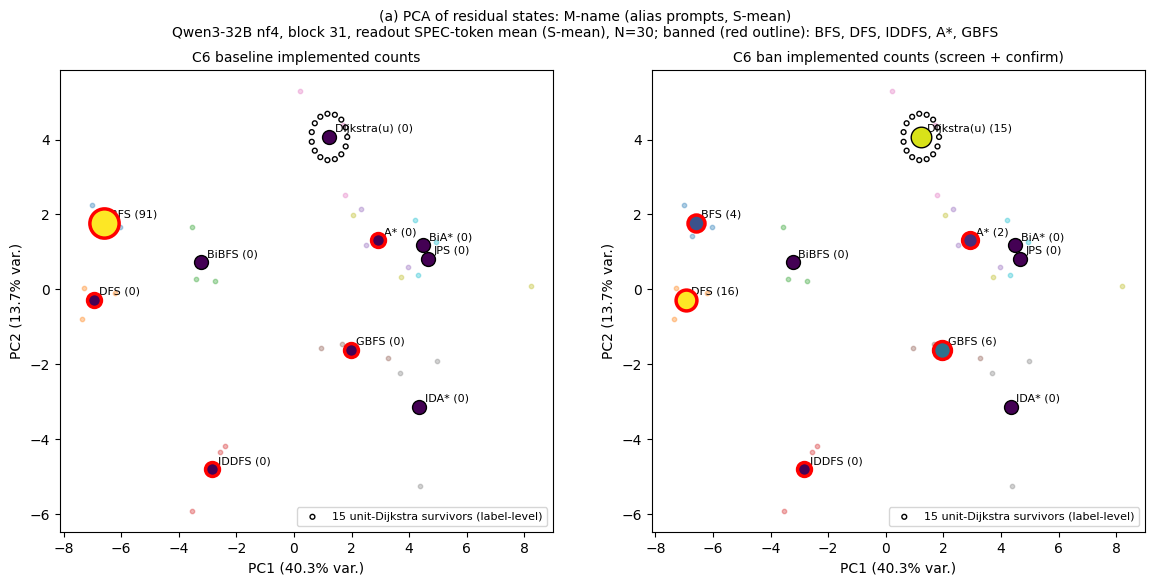

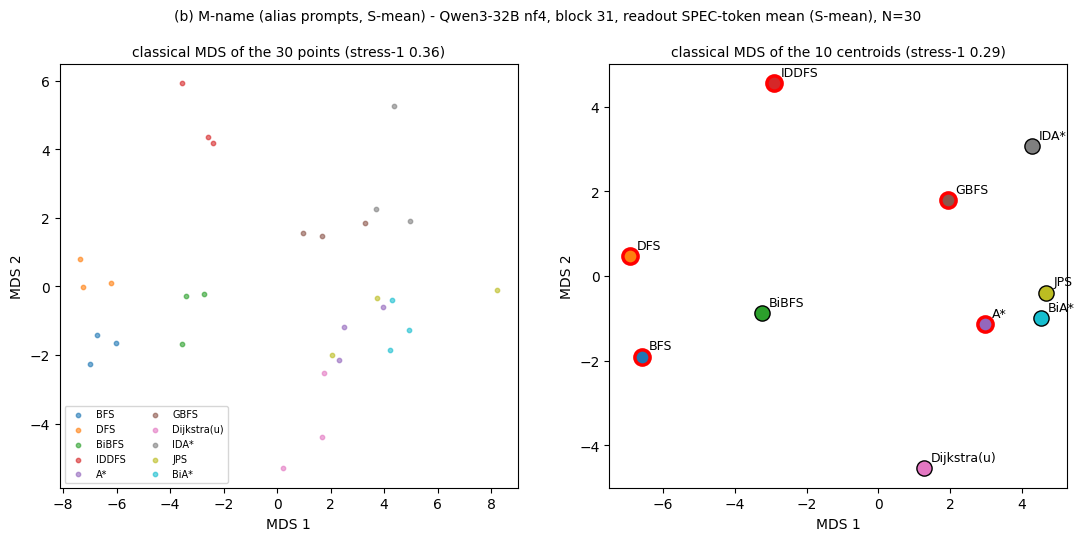

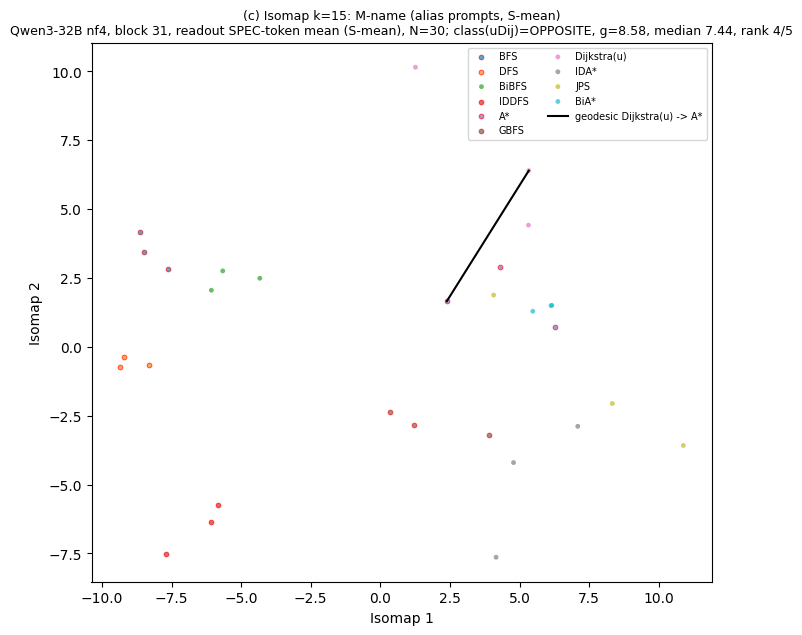

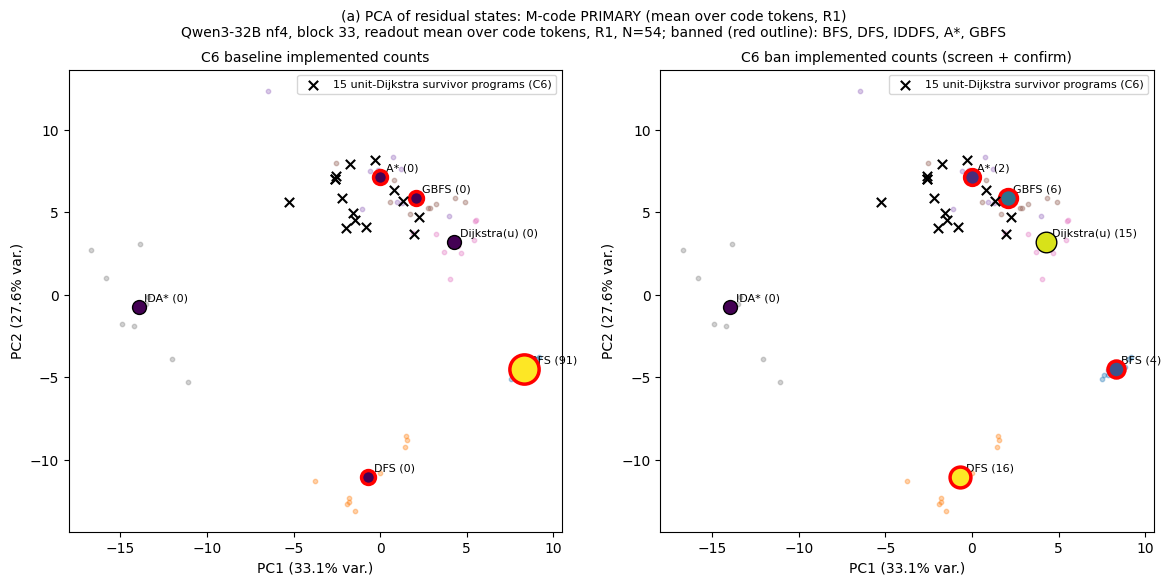

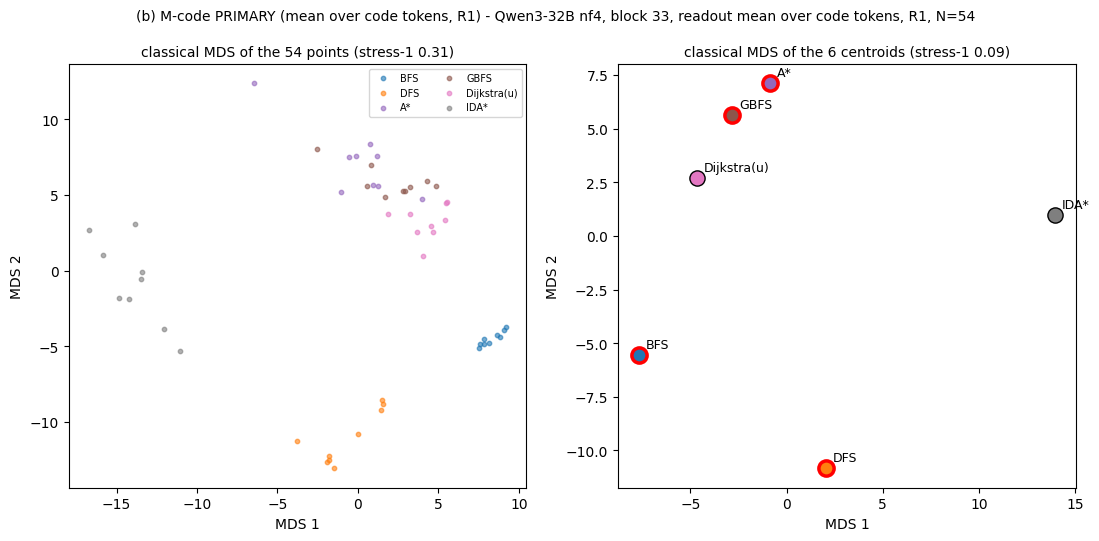

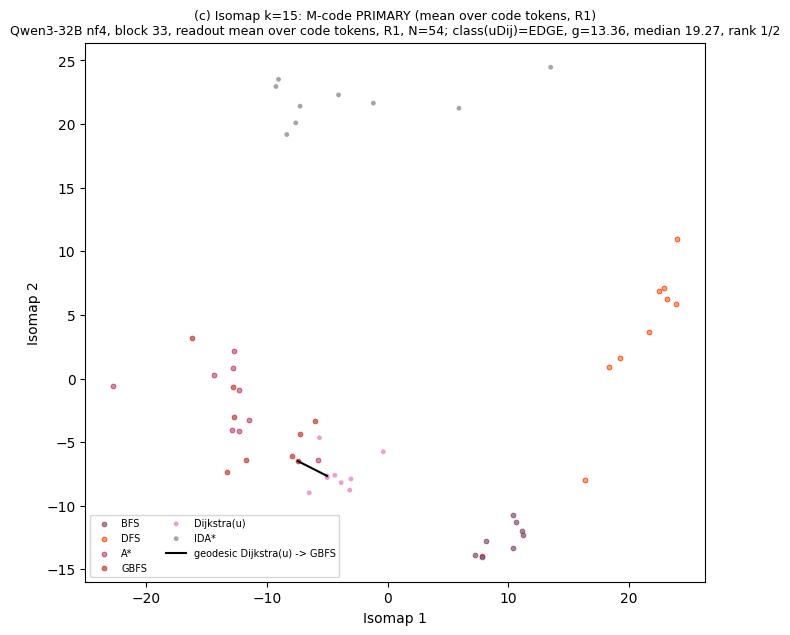

In [21]:
for key, r in geo_results.items():
    m_tag, name = key.split("|")
    manifold_figs(m_tag, name, r)

### Class table, RDM heatmaps, behavioural map and the alias-level lexical plot

`class_table`, `rdm_figs` and `lexical_fig` from `src/stage_figures.py`, reading the in-memory results:

* **Class table**: for each manifold, every non-banned algorithm's class and g / median at k = 15 (bold: unit Dijkstra).
* **RDMs**: the three model RDMs (behaviour, alias lexicon, program surface) next to the neural class-geodesic RDMs. M-code has only 6 classes, because the other algorithms have fewer than 10 verified programs; their rows are blank.
* **Behavioural MDS**: drawn in behavioural coordinates, not activations. By construction, unit Dijkstra expands cells in BFS order on a unit grid.
* **Lexical plot**: each alias of a non-banned algorithm, its L1 (how many banned names it contains) against its g_alias.

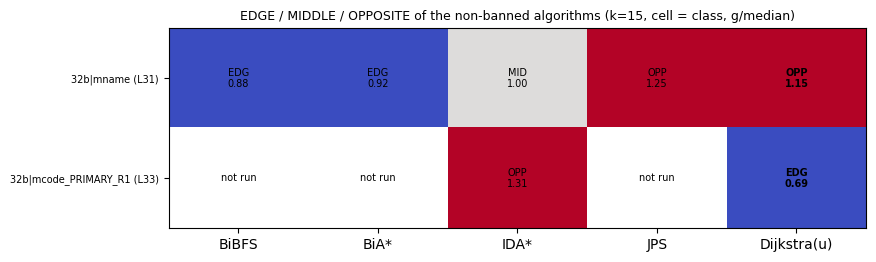

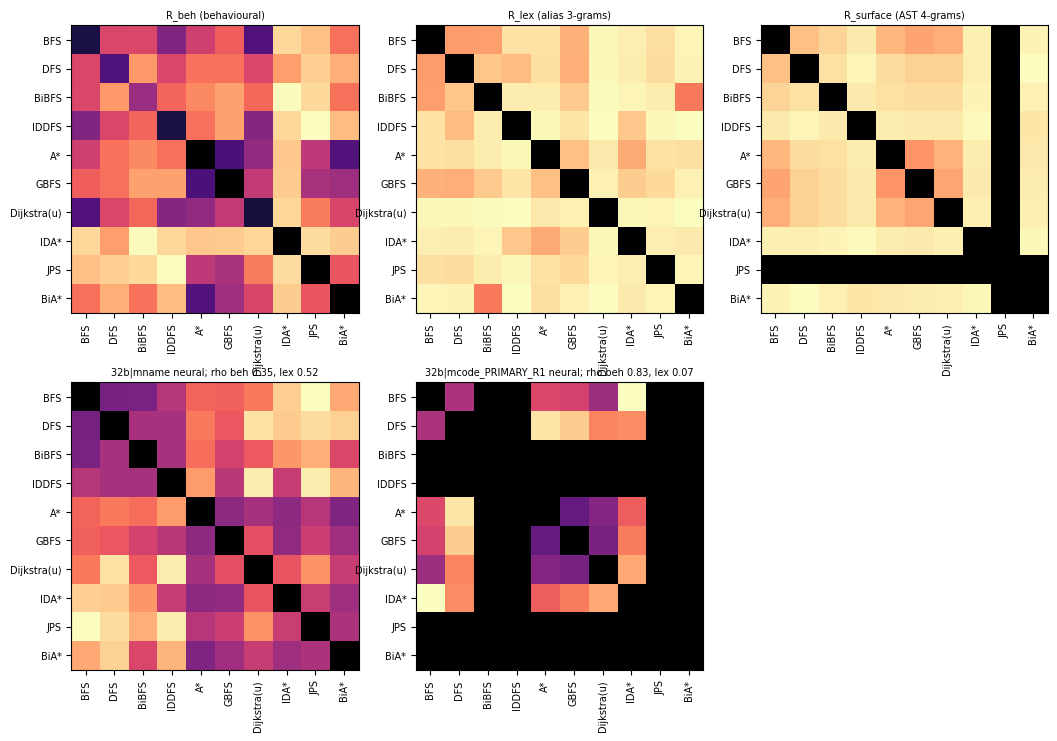

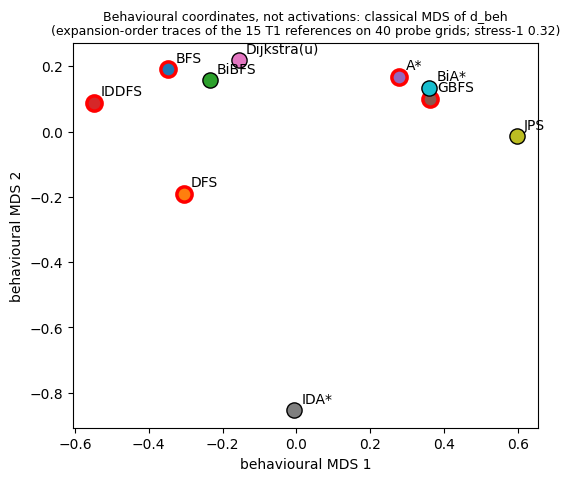

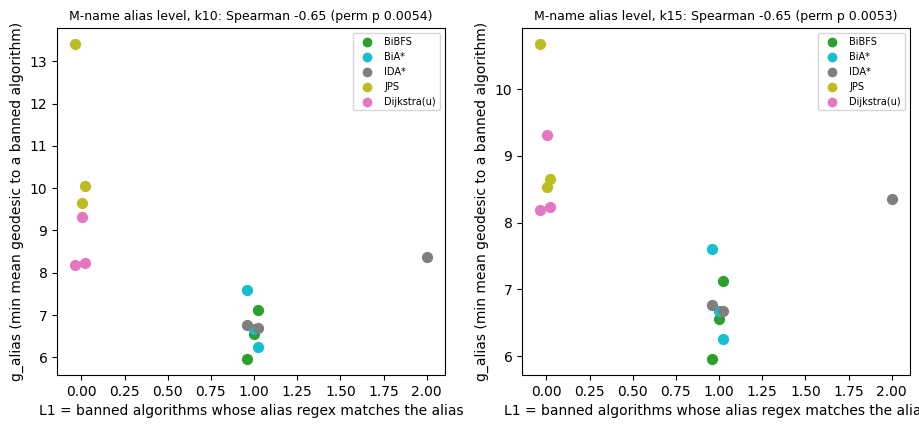

In [22]:
def class_table(geo_all: dict[str, Any]) -> None:
    rows, cells, txt = [], [], []
    cmap = {"EDGE": 0, "MIDDLE": 1, "OPPOSITE": 2}
    for key, r in geo_all.items():
        if r is None:
            continue
        kd = r["L_star"]["describe"][f"k{K_VERDICT}"]
        rows.append(f"{key} (L{r['L_star']['block']})")
        cells.append([cmap.get(kd["classes"].get(a), np.nan) for a in NB5])
        txt.append([(f"{kd['classes'][a][:3]}\n{kd['g'][a] / kd['median']:.2f}" if a in kd["classes"] else "not run")
                    for a in NB5])
    if not rows:
        return
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(rows) + 1.5))
    ax.imshow(np.array(cells, dtype=float), cmap="coolwarm", vmin=0, vmax=2, aspect="auto")
    for i in range(len(rows)):
        for j in range(5):
            ax.text(j, i, txt[i][j], ha="center", va="center", fontsize=7,
                    fontweight="bold" if NB5[j] == UDIJ else "normal")
    ax.set_xticks(range(5), [SHORT[a] for a in NB5])
    ax.set_yticks(range(len(rows)), rows, fontsize=7)
    ax.set_title(f"EDGE / MIDDLE / OPPOSITE of the non-banned algorithms (k={K_VERDICT}, cell = class, g/median)",
                 fontsize=9)
    _save(fig, "class_table")


def rdm_figs() -> None:
    rs = rsa_results                       # notebook: in memory (original: results/rsa.json)
    md = meta["model_rdms"]                # notebook: demo data (original: results/behavioural_distance.json, ...)
    mats = {"R_beh (behavioural)": np.array(md["R_beh"], dtype=float),
            "R_lex (alias 3-grams)": np.array(md["R_lex"], dtype=float)}
    mats["R_surface (AST 4-grams)"] = np.array(md["R_surface"], dtype=float)
    geo_all = geo_results                  # notebook: in memory (original: results/geometry_all.json)
    for key in ("32b|mname", "32b|mdesc", "32b|mlex", "32b|mcode_PRIMARY_R1"):
        if key in geo_all:
            M = np.array(geo_all[key]["L_star"]["describe"][f"k{K_VERDICT}"]["class_geodesic_matrix"])
            M = (M + M.T) / 2
            np.fill_diagonal(M, 0)
            r = rs.get(key, {}).get("models", {})
            lab = f"{key} neural; rho beh {r.get('R_beh', {}).get('rho', float('nan')):.2f}, lex " \
                  f"{r.get('R_lex', {}).get('rho', float('nan')):.2f}"
            mats[lab] = M
    n = len(mats)
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(4.2 * ((n + 1) // 2), 8.5))
    for ax, (t, M) in zip(axes.ravel(), mats.items()):
        ax.imshow(np.nan_to_num(M), cmap="magma")
        ax.set_xticks(range(10), [SHORT[a] for a in CANON_ORDER], rotation=90, fontsize=7)
        ax.set_yticks(range(10), [SHORT[a] for a in CANON_ORDER], fontsize=7)
        ax.set_title(t, fontsize=7)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    _save(fig, "rdms")
    Y = meta["behavioural_mds"]["coordinates"]
    fig, ax = plt.subplots(figsize=(6, 5))
    for a in CANON_ORDER:
        ax.scatter([Y[a][0]], [Y[a][1]], s=120, color=COL[a], edgecolors="red" if a in B5 else "black",
                   linewidths=2.5 if a in B5 else 1)
        ax.annotate(SHORT[a], Y[a], xytext=(5, 5), textcoords="offset points")
    ax.set_title(f"Behavioural coordinates, not activations: classical MDS of d_beh\n(expansion-order traces of the "
                 f"15 T1 references on 40 probe grids; stress-1 {meta['behavioural_mds']['stress1']:.2f})", fontsize=9)
    ax.set_xlabel("behavioural MDS 1")
    ax.set_ylabel("behavioural MDS 2")
    _save(fig, "behavioural_mds")


def lexical_fig() -> None:
    lr = lex_results                       # notebook: in memory (original: results/lexical_regression.json)
    r = lr.get("32b|mname")
    if not r:
        return
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, k in zip(axes, ("k10", "k15")):
        rows = r[k]["rows"]
        for row in rows:
            ax.scatter(row["L1"] + np.random.default_rng(len(row["alias"] if "alias" in row else "") + row[
                "alias_index"]).uniform(-0.08, 0.08), row["g_alias"], color=COL[row["algorithm"]], s=50)
        for a in NB5:
            ax.scatter([], [], color=COL[a], label=SHORT[a])
        ax.set_xlabel("L1 = banned algorithms whose alias regex matches the alias")
        ax.set_ylabel("g_alias (min mean geodesic to a banned algorithm)")
        ax.set_title(f"M-name alias level, {k}: Spearman {r[k]['spearman_L1']:.2f} (perm p {r[k]['perm_p_L1']:.4f})",
                     fontsize=9)
        ax.legend(fontsize=7)
    _save(fig, "lexical_alias_level_32b")


class_table(geo_results)
rdm_figs()
lexical_fig()

## Results: the demo subset against the full run

The table below puts every headline number computed above next to the artifact's full-run value: all 300 M-name prompts, all 117 M-code programs, and the same resampling counts. Those values are read from `metadata.full_run_reference` in the demo data.

The figure shows both manifolds side by side in Isomap coordinates: the same model, the same algorithm (unit Dijkstra, black outline) and the same banned five (red outline).

* On the map of **names**, unit Dijkstra sits OPPOSITE the banned five.
* On the map of **programs**, it sits at their EDGE. The 15 programs Qwen3-32B actually wrote under the ban (crosses, embedded out of sample) land there too.

How far the demo subset can be trusted:

* **What reproduces.** The classes, the pooled landing verdicts at k = 15, the RSA ordering (M-name: R_lex above R_beh; M-code: R_beh and R_surface far above R_lex), P4 and P8 all match the full run.
* **What differs in size.** The M-name subset has only 3 prompts per algorithm, so its g / median ratios are smaller (1.1 vs 1.6) and its k = 10 landing verdict is NEITHER rather than OPPOSITE.
* **Placement nearest neighbour.** The M-code frame here has 9 rather than 20 programs per algorithm. So each survivor's single nearest algorithm is mostly A\* or GBFS instead of unit Dijkstra (13 of 15 in the full run), although all 15 still land on the EDGE side.

Where does unit-weight Dijkstra sit relative to the banned five?
demo = this notebook on the 99-point subset; full = the artifact's run on all points (300 M-name, 117 M-code)

manifold               k | class: demo      full | rank: demo  full | g/median: demo  full | nearest banned: demo   full
32b|mname              5 |    OPPOSITE    MIDDLE |        4/5   3/5 |           1.00  1.00 |                   A*  IDDFS
32b|mname             10 |    OPPOSITE  OPPOSITE |        4/5   5/5 |           1.12  1.78 |                   A*  IDDFS
32b|mname             15 |    OPPOSITE  OPPOSITE |        4/5   5/5 |           1.15  1.63 |                   A*     A*
32b|mcode_PRIMARY_R1   5 |        EDGE      EDGE |        1/2   1/2 |           0.60  0.73 |                 GBFS   GBFS
32b|mcode_PRIMARY_R1  10 |        EDGE      EDGE |        1/2   1/2 |           0.68  0.64 |                 GBFS   GBFS
32b|mcode_PRIMARY_R1  15 |        EDGE      EDGE |        1/2   1/2 |           0.69  0.67 |      

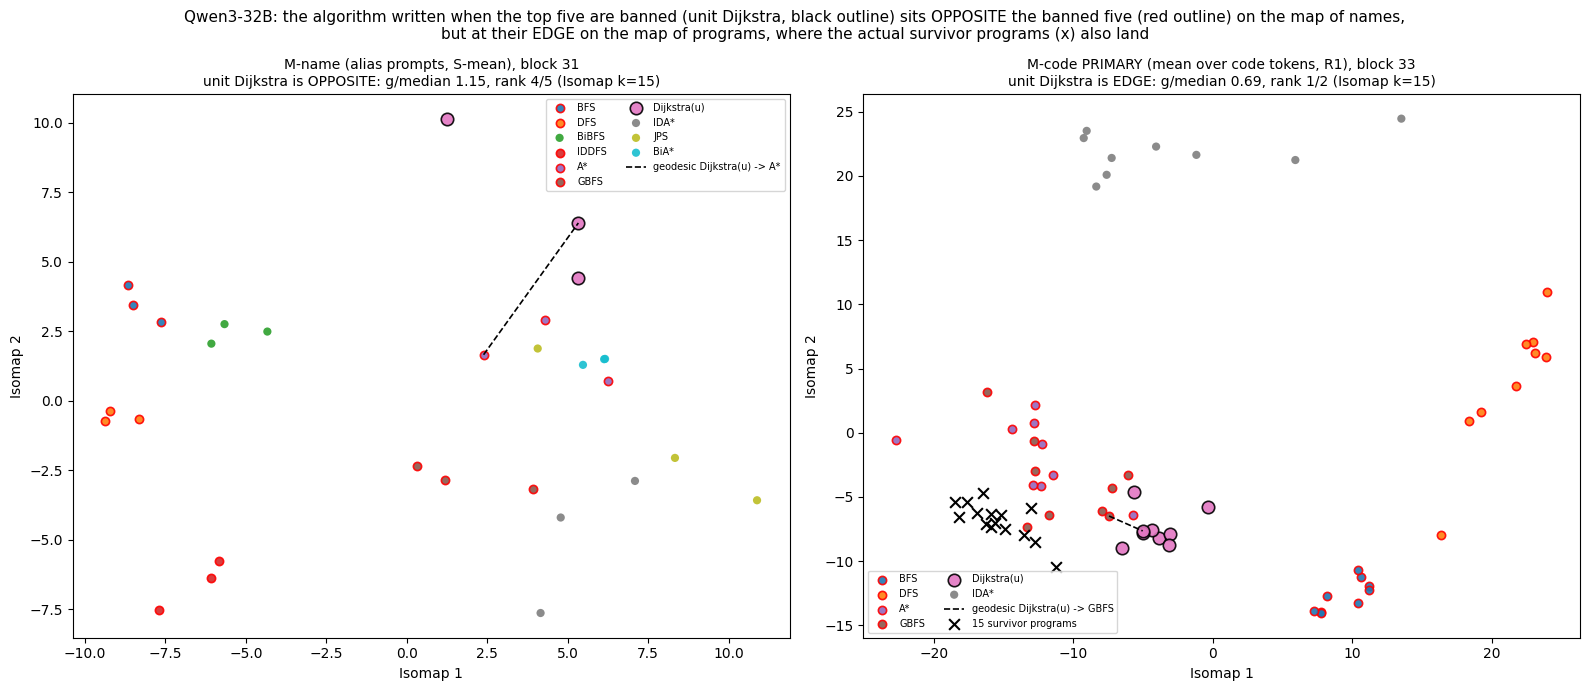

In [23]:
# ---------------------------------------------------------------------------------------------- demo vs full run
ref = meta["full_run_reference"]
KEYS = ["32b|mname", "32b|mcode_PRIMARY_R1"]
print("Where does unit-weight Dijkstra sit relative to the banned five?")
print("demo = this notebook on the 99-point subset; full = the artifact's run on all points (300 M-name, 117 M-code)\n")
print(f"{'manifold':21s}{'k':>3s} | {'class: demo':>11s} {'full':>9s} | {'rank: demo':>10s} {'full':>5s} | "
      f"{'g/median: demo':>14s} {'full':>5s} | {'nearest banned: demo':>20s} {'full':>6s}")
for key in KEYS:
    sd, sf = geo_results[key]["summary"], ref["geometry"][key]["summary"]
    n_nb = len(geo_results[key]["L_star"]["describe"]["nonbanned_used"])
    for k in KS:
        a, b = sd[f"k{k}"], sf[f"k{k}"]
        print(f"{key:21s}{k:3d} | {a['udij_class']:>11s} {b['udij_class']:>9s} | {a['udij_rank']:>8d}/{n_nb} "
              f"{b['udij_rank']:>3d}/{n_nb} | {a['udij_ratio']:14.2f} {b['udij_ratio']:5.2f} | "
              f"{SHORT[a['udij_nearest_banned']]:>20s} {SHORT[b['udij_nearest_banned']]:>6s}")

print(f"\nLanding verdict (15 pooled survivors) and stability, k = {K_VERDICT}")
for key in KEYS:
    r, f = geo_results[key]["L_star"], ref["geometry"][key]
    bd, bf = r["bootstrap"][f"k{K_VERDICT}"], f["bootstrap_k15"]
    print(f"  {key:21s} landing demo {r['landing'][f'k{K_VERDICT}']['pooled']['verdict']:8s} full "
          f"{f['landing_pooled_verdict']['k15']:8s} | bootstrap P(EDGE) demo {bd['edge_probability'][UDIJ]:.2f} "
          f"(n={bd['n_boot']}) full {bf['edge_probability'][UDIJ]:.2f} (n={bf['n_boot']}) | split-half S-B demo "
          f"{r['split_half'][f'k{K_VERDICT}']['spearman_brown']:.2f} full {f['split_half_spearman_brown_k15']:.2f}")

print("\nRSA: Spearman rho of the class-geodesic RDM with each model RDM (exact Mantel p)")
for key in KEYS:
    parts = []
    for mn in ("R_lex", "R_beh", "R_surface"):
        d, f = rsa_results[key]["models"][mn], ref["rsa"][key][mn]
        parts.append(f"{mn} demo {d['rho']:+.2f} (p {d['p_exact']:.3f}) full {f['rho']:+.2f} (p {f['p_exact']:.3f})")
    print(f"  {key:21s} " + " | ".join(parts))

lx_d, lx_f = lex_results["32b|mname"], ref["lexical_regression"]["32b|mname"]
print(f"\nP4, M-name alias level, Spearman(g_alias, L1): demo k10 {lx_d['k10']['spearman_L1']:+.2f}, k15 "
      f"{lx_d['k15']['spearman_L1']:+.2f} (pass {lx_d['P4_pass']}) | full k10 {lx_f['k10']['spearman_L1']:+.2f}, k15 "
      f"{lx_f['k15']['spearman_L1']:+.2f} (pass {lx_f['P4_pass']})")
pl_d, pl_f = placement_results["32b|mcode_PRIMARY_R1"], ref["placement"]["32b|mcode_PRIMARY_R1"]
print(f"P8, survivor programs placed at the EDGE of M-code: demo {pl_d['udij_survivors']['n_edge']}/"
      f"{pl_d['udij_survivors']['n']} (LOO accuracy {pl_d['G_place']['loo_accuracy']:.2f}) | full "
      f"{pl_f['udij_survivors']['n_edge']}/{pl_f['udij_survivors']['n']} (LOO accuracy {pl_f['G_place']['loo_accuracy']:.2f})")
print("    their nearest algorithm: demo " + ", ".join(
    f"{SHORT[a]} {c}" for a, c in pl_d["udij_survivors"]["nearest_algorithm_counts"].items() if c) + " | full " + ", ".join(
    f"{SHORT[a]} {c}" for a, c in pl_f["udij_survivors"]["nearest_algorithm_counts"].items() if c))

n4 = ref["n4_verdict"]
print("\nFull run, k = 15 class of unit Dijkstra on every manifold analysed: " + ", ".join(
    f"{k} {v['k15']['udij_class']}" for k, v in n4["verdict_table"].items() if v["k15"]["udij_class"]))
print(f"Full-run named outcome: {n4['named_outcome']} (M-code {n4['mcode_class_k15']}, M-desc {n4['mdesc_class_k15']}); "
      f"predictions {n4['predictions_pass']}")
print(f"\nNotebook run time so far: {time.time() - T0:.0f} s")

# ---------------------------------------------------------------------------------------------- one picture
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, key in zip(axes, KEYS):
    m_tag, name = key.split("|")
    z = COORDS[f"{m_tag}_{name}"]
    Y, labels = z["iso"], z["labels"]
    kd = geo_results[key]["L_star"]["describe"][f"k{K_VERDICT}"]
    for a in [a for a in CANON_ORDER if a in set(labels.tolist())]:
        s = labels == a
        ax.scatter(Y[s, 0], Y[s, 1], s=80 if a == UDIJ else 35, color=COL[a], alpha=0.9, label=SHORT[a],
                   edgecolors="red" if a in B5 else ("black" if a == UDIJ else "none"), linewidths=1.2)
    # geodesic from unit Dijkstra to its nearest banned algorithm, traced on the kNN graph (as in figure (c))
    nb = kd["nearest_banned"][UDIJ]
    iu, ib = np.where(labels == UDIJ)[0], np.where(labels == nb)[0]
    i, j = np.unravel_index(np.argmin(z["geo"][np.ix_(iu, ib)]), (len(iu), len(ib)))
    _, pred = shortest_path(FROZEN[f"geo_{m_tag}_{name}_k{K_VERDICT}"]["adjacency"], method="D", directed=False,
                            indices=[iu[i]], return_predecessors=True)
    path, cur = [], ib[j]
    while cur >= 0 and cur != iu[i]:
        path.append(cur)
        cur = pred[0, cur]
    path.append(iu[i])
    ax.plot(Y[path, 0], Y[path, 1], "k--", lw=1.2, label=f"geodesic {SHORT[UDIJ]} -> {SHORT[nb]}")
    if name.startswith("mcode"):
        # the 15 survivor programs, embedded out of sample by the fitted Isomap
        sel = [e for e in data["examples"] if e["manifold"] == "placement_SURV"]
        Q = np.stack([np.frombuffer(base64.b64decode(e["x_f16_b64"]), dtype="<f2") for e in sel]).astype(np.float64)
        Yq = z["isomap_model"].transform(Q)
        ax.scatter(Yq[:, 0], Yq[:, 1], marker="x", s=60, color="black", label=f"{len(sel)} survivor programs")
    ax.set_title(f"{TITLES[name]}, block {z['block']}\nunit Dijkstra is {kd['classes'][UDIJ]}: "
                 f"g/median {kd['udij_ratio']:.2f}, rank {kd['udij_rank']}/{len(kd['g'])} (Isomap k={K_VERDICT})",
                 fontsize=10)
    ax.set_xlabel("Isomap 1")
    ax.set_ylabel("Isomap 2")
    ax.legend(fontsize=7, ncol=2, loc="best")
fig.suptitle("Qwen3-32B: the algorithm written when the top five are banned (unit Dijkstra, black outline) sits "
             "OPPOSITE the banned five (red outline) on the map of names,\nbut at their EDGE on the map of programs, "
             "where the actual survivor programs (x) also land", fontsize=11)
plt.tight_layout()
plt.show()

## Scaling back to the full run

* **Parameters.** The config cell already holds the committed values (k = 5 / 10 / 15, 1,000 bootstrap resamples, 10,000 landing-null draws, 100,000 permutations). For a quick check they can be lowered to `N_BOOT_32B = N_BOOT_OTHER = 10`, `LANDING_DRAWS = PERM_P_N = 1000`.
* **Data.** The full analysis uses all 300 M-name, 260 M-desc, 300 M-lex and 117 M-code states at every block from 17 to 47 (`cache/states/`, about 0.5 GB of float16 arrays), plus the Qwen3-8B states. These files stay on the run's storage volume and are not in the published repository. The artifact's GPU stages rebuild them: `method.py mname 32b`, `method.py states 32b mlex ban` and `method.py states 32b mdesc mcode`, about 30 GPU-minutes on one RTX 5090. Then run `method.py blocks`, `method.py analyse`, `method.py figures` and `method.py outputs`.
* **What changes with the data.** Several parts need those states: layer selection (`blocks`), the reference-block section, the 5-block robustness grid, name evocation, and the Qwen3-8B / M-desc / M-lex manifolds. Every function in this notebook runs on the states unchanged once `load_manifold` reads the `.npz` files again (the original `load_manifold` of `src/stage_analysis.py`).
* **Rebuilding the demo data.** `scripts/build_mini_demo_data.py --src <artifact folder>` regenerates `mini_demo_data.json` from the artifact's cached states. `--mname-templates` and `--mcode-per-alg` choose a different subset.

The geometry is correlational: it describes where representations and survivors sit, not whether the model uses this geometry to choose an algorithm.